# Project 10 – Open-Domain Question Answering: From Lexical Retrieval to RAG
### End-to-end notebook: Task 1 (BM25 + extraction) → Task 2 (RAG) → Task 3 (hybrid retrieval + groundedness check)

**Dataset:** [`rag-datasets/rag-mini-wikipedia`](https://huggingface.co/datasets/rag-datasets/rag-mini-wikipedia)   
**Group:** 28   
**Name:** Nihar Ranjan Das  
**Roll.No:** 26AI60R20

This single notebook runs the whole project from start to finish. The passage index, the questions and the evaluation code are loaded and defined **once** (Part 0) and shared by all three tasks, so every number is computed on exactly the same data with exactly the same metric code. Task 2 and Task 3 use the rankings and answers of the earlier tasks directly from memory; no files have to be uploaded between tasks.

### The three tasks
| Task | Retriever | Reader | Extra analysis |
|---|---|---|---|
| **1 · Baseline** | BM25 (`rank_bm25`, k1 = 1.5, b = 0.75), top-5 | extractive: best sentence of the top passage → longest noun phrase / number span | error analysis, variant that skips question words |
| **2 · Paper reproduction (RAG)** | `all-MiniLM-L6-v2` + FAISS flat index (cosine), top-5 | `Qwen/Qwen2.5-1.5B-Instruct`, passages truncated to 200 tokens, ≤ 64 new tokens, temperature 0 | retrieval vs. generation errors, yes/no analysis |
| **3 · Combine & improve** | Reciprocal Rank Fusion of BM25 + dense (constant 60), top-5 | same LLM, prompt and decoding as Task 2 | lexical-overlap groundedness check, abstention, threshold sweep, McNemar tests |

Every system is scored with **Exact Match**, **token F1** and **Recall@k** (k ∈ {1, 3, 5, 10}) on the 918 questions, over the same 3,200-passage index.

### How to run
- **Google Colab (recommended):** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`. A full run takes about 10–15 minutes, most of it LLM answer generation (Task 2 and Task 3).
- **Locally:** open the notebook in Jupyter from the project folder and run all cells. A CUDA GPU is recommended; on a CPU everything works, but generation is much slower.
- **Smoke test:** set `QUICK_TEST = True` in Section 0.1 to run every task on the first 40 questions only (nothing is saved).
- **Generation cache:** the LLM answers are cached in the output folder together with a fingerprint of every setting that affects them (model, prompt, top-k, token limits, batch size, dataset revision, questions, rankings). If the folder already holds caches made with identical settings, for example the submitted `Output_Final/` folder, generation is skipped; a cache made with other settings is ignored automatically. `RESET_CACHE = True` forces fresh generation.

### Output files (written to `Output_Final/`)
| File | Produced by | Content |
|---|---|---|
| `task1_results.json` | Task 1 | BM25 top-100 rankings, baseline and variant predictions, metrics, config |
| `task1_recall.png` | Task 1 | BM25 Recall@k |
| `task2_results.json` | Task 2 | dense top-100 rankings, generated answers, metrics, generation settings |
| `task2_generation_cache.json` | Task 2 | resumable cache of the Task 2 LLM answers |
| `task2_recall.png` | Task 2 | dense vs. BM25 Recall@k |
| `task3_results.json` | Task 3 | fused rankings, hybrid answers, comparison and groundedness tables, overlap scores, threshold sweep |
| `task3_hybrid_generation_cache.json` | Task 3 | resumable cache of the hybrid LLM answers |
| `task3_recall_compare.png`, `task3_overlap_hist.png`, `task3_threshold_sweep.png` | Task 3 | Recall@k of the three retrievers, overlap histogram, threshold sweep |

### Contents
**Part 0 – Shared setup**
- 0.1 Setup and settings
- 0.2 Loading the data
- 0.3 Evaluation helpers
- 0.4 A first look at the data

**Part 1 – Task 1: Classical lexical retrieve-and-extract**
- 1.1 Retrieval with BM25
- 1.2 Extractive answering
- 1.3 Evaluation
- 1.4 Error analysis
- 1.5 Additional experiment: skipping spans that repeat the question
- 1.6 Recall@k plot and example predictions
- 1.7 Saving the results
- 1.8 Discussion

**Part 2 – Task 2: Retrieval-Augmented Generation**
- 2.1 Dense retrieval
- 2.2 Answer generation
- 2.3 Evaluation
- 2.4 Error analysis: retrieval vs. generation
- 2.5 Comparison with Task 1
- 2.6 Additional checks
- 2.7 Recall@k plot and example predictions
- 2.8 Saving the results
- 2.9 Discussion

**Part 3 – Task 3: Hybrid retrieval with groundedness verification**
- 3.1 Hybrid retrieval with Reciprocal Rank Fusion
- 3.2 Answering with the hybrid top-5
- 3.3 Comparison: Task 1 vs. Task 2 vs. Task 3
- 3.4 Groundedness check
- 3.5 The check on the hybrid answers, and examples
- 3.6 Significance tests and further analysis
- 3.7 Saving the results
- 3.8 Discussion

**Part 4 – Final summary**
- 4.1 Results across the three tasks
- 4.2 Output files
- 4.3 Overall conclusions

**References**

---
# Part 0 – Shared setup
Everything in this part is used by all three tasks: the libraries, the settings, the passage index, the questions and the evaluation code.

## 0.1 Setup and settings
We install the libraries that are not pre-installed on Colab and pin the versions that affect the results (`rank_bm25` and the spaCy model). Random seeds are fixed, and every random example table uses its own seeded generator, so a re-run reproduces our numbers.

All settings required by the project brief are defined once in this cell:

| Setting | Value | Used in | Meaning |
|---|---|---|---|
| `DATASET_REVISION` | `1f9f3b5…` | all | fixed version of the dataset |
| `TOP_K` | 5 | all | retrieval depth / passages given to the LLM |
| `KS` | 1, 3, 5, 10 | all | cut-offs for Recall@k |
| `KEEP_N` | 100 | all | length of every saved ranking (needed for Recall@10 and for the fusion in Task 3) |
| `BM25_K1`, `BM25_B` | 1.5, 0.75 | Task 1 | BM25 term-frequency saturation and length normalisation |
| `EMBED_MODEL` | `all-MiniLM-L6-v2` | Task 2 | sentence encoder for dense retrieval |
| `LLM_NAME` | `Qwen/Qwen2.5-1.5B-Instruct` | Tasks 2, 3 | open instruction-tuned generator (fits a free T4 in float16) |
| `PASSAGE_MAX_TOKENS` | 200 | Tasks 2, 3 | each passage is truncated to 200 LLM tokens |
| `MAX_NEW_TOKENS` | 64 | Tasks 2, 3 | maximum answer length (greedy decoding = temperature 0) |
| `BATCH_SIZE` | 8 | Tasks 2, 3 | prompts generated together; identical for both tasks |
| `RRF_C` | 60 | Task 3 | Reciprocal Rank Fusion constant |
| `THRESH` | 0.5 | Task 3 | overlap ≥ 0.5 counts as grounded; below it the answer is flagged |
| `CORRECT_F1` | 0.5 | Task 3 | an answer counts as correct if its token F1 is at least 0.5 |

Run options: `USE_DRIVE` (save to Google Drive in Colab), `QUICK_TEST` (first 40 questions only) and `RESET_CACHE` (ignore cached LLM answers).

In [3]:
# Pinned versions so Colab and local runs give identical results
%pip install -q datasets rank_bm25==0.2.2 "spacy>=3.8,<3.9" sentence-transformers faiss-cpu "transformers>=4.56" accelerate scikit-learn
%pip install -q https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl

import os, re, sys, json, string, collections, random, time, unicodedata, hashlib, math
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display

SEED = 42
random.seed(SEED); np.random.seed(SEED)      # reproducibility

# ---- Where the results are written ----
USE_DRIVE = False          # True = save to Google Drive (Colab only); False = local Output_Final/ folder
try:
    from google.colab import drive, files
    IN_COLAB = True
except ImportError:        # running locally instead of Colab
    IN_COLAB = False
OUT = 'Output_Final'
if IN_COLAB and USE_DRIVE:
    try:
        drive.mount('/content/drive')
        OUT = '/content/drive/MyDrive/NLP_Project_2/Output_Final'
    except Exception as e:                   # e.g. authorisation declined or timed out
        print('Google Drive not mounted, using local Output_Final/ instead:', e)
os.makedirs(OUT, exist_ok=True)
print('Saving results to', os.path.abspath(OUT))

# ---- Shared settings (identical for all three tasks) ----
DATASET_REVISION = '1f9f3b53fbc5995b85aab8e993504ad42c5f16f6'   # pinned dataset version
TOP_K  = 5                 # retrieval depth; passages given to the LLM in Tasks 2 and 3
KS     = [1, 3, 5, 10]     # Recall@k values to report
KEEP_N = 100               # length of every saved ranking (Recall@10 + RRF fusion in Task 3)

# ---- Task 1: BM25 ----
BM25_K1, BM25_B = 1.5, 0.75

# ---- Task 2: dense retrieval + LLM generation (Task 3 reuses the generation settings) ----
EMBED_MODEL = 'sentence-transformers/all-MiniLM-L6-v2'
LLM_NAME = 'Qwen/Qwen2.5-1.5B-Instruct'      # open instruction-tuned LLM
PASSAGE_MAX_TOKENS = 200   # each passage truncated to 200 tokens
MAX_NEW_TOKENS = 64        # answer length limit
BATCH_SIZE = 8             # same for Task 2 and Task 3: with fp16 + padding, a different batch size can
                           # change a few greedy answers (lower to 4 or 2 only for 'CUDA out of memory')

# ---- Task 3: fusion + groundedness check ----
RRF_C = 60                 # Reciprocal Rank Fusion constant
THRESH = 0.5               # overlap >= THRESH counts as 'grounded'; below it is flagged
CORRECT_F1 = 0.5           # an answer counts as 'correct' if token F1 >= 0.5

# ---- Run options ----
QUICK_TEST = False         # True = run every task on the first 40 questions only (nothing is saved)
RESET_CACHE = False        # True = ignore any saved LLM answers and generate everything again

Saving results to /content/Output_Final


## 0.2 Loading the data
The dataset has two configurations, and we load both:
- `text-corpus`: 3,200 Wikipedia passages, which form our retrieval index;
- `question-answer`: 918 questions with gold answers, used for all evaluation.

The passages are indexed exactly as provided, with no re-chunking. BM25 (Task 1) and the dense retriever (Task 2) index this same list in the same order, and all rankings are stored as positions in it.

**Encoding repair.** While inspecting the corpus we noticed that 483 passages contain mis-encoded characters: UTF-8 text that was decoded as Latin-1, for example `Lincolnâ\x80\x99s` instead of *Lincoln’s*, or `RÃ\xado de la Plata` instead of *Río de la Plata*. Because the gold answers are clean, these passages could never match them. We therefore reverse the wrong decoding when loading the data (`fix_mojibake`). This only corrects characters: the number, order and boundaries of the passages are unchanged, and the questions and answers need no repair.

In [2]:
from datasets import load_dataset

corpus = load_dataset('rag-datasets/rag-mini-wikipedia', 'text-corpus', revision=DATASET_REVISION)
qa     = load_dataset('rag-datasets/rag-mini-wikipedia', 'question-answer', revision=DATASET_REVISION)
print(corpus)
print(qa)

def fix_mojibake(s):
    # the dataset has UTF-8 text decoded as Latin-1, e.g. 'Lincolnâ\x80\x99s' instead of 'Lincoln’s'
    try:
        return s.encode('latin-1').decode('utf-8')
    except (UnicodeEncodeError, UnicodeDecodeError):
        return s                             # already clean - keep as is

raw_passages = [str(p) for p in corpus['passages']['passage']]
passages    = [fix_mojibake(p) for p in raw_passages]
passage_ids = list(corpus['passages']['id'])  # saved with the rankings, which are list positions
questions   = [fix_mojibake(str(q)) for q in qa['test']['question']]
answers     = [fix_mojibake(str(a)) for a in qa['test']['answer']]
if QUICK_TEST:
    questions, answers = questions[:40], answers[:40]

print(len(passages), 'passages |', len(questions), 'questions')
print('passages repaired (mojibake):', sum(p != r for p, r in zip(passages, raw_passages)))
print('Example Q:', questions[0], '->', answers[0])

README.md:   0%|          | 0.00/719 [00:00<?, ?B/s]

data/passages.parquet/part.0.parquet: reconstructing file:   0%|          |  0.00B /  797kB            

data/passages.parquet/part.0.parquet: downloading bytes:           |  0.00B            

Generating passages split: 0 examples [00:00, ? examples/s]

data/test.parquet/part.0.parquet: reconstructing file:   0%|          |  0.00B / 54.4kB            

data/test.parquet/part.0.parquet: downloading bytes:           |  0.00B            

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    passages: Dataset({
        features: ['passage', 'id'],
        num_rows: 3200
    })
})
DatasetDict({
    test: Dataset({
        features: ['question', 'answer', 'id'],
        num_rows: 918
    })
})
3200 passages | 918 questions
passages repaired (mojibake): 483
Example Q: Was Abraham Lincoln the sixteenth President of the United States? -> yes


## 0.3 Evaluation helpers
This code is shared by all three tasks, so the results of Tasks 1–3 are directly comparable.

- **Normalisation (SQuAD-style):** lowercase, remove punctuation, remove the articles *a/an/the*, collapse whitespace. We remove Unicode punctuation as well as ASCII (e.g. ’ – “ ”), because the repaired passages contain typographic quotes and dashes.
- **Exact Match (EM):** 1 if the normalised prediction equals the normalised gold answer, otherwise 0.
- **Token F1:** harmonic mean of token-level precision and recall between the prediction and the gold answer.
- **Recall@k:** the dataset does not say which passage contains the answer. Following the answer-string convention used for DPR, a question counts as a hit if its normalised gold answer appears as whole words in at least one of the top-k passages. Passages are normalised once and cached, and we compute the rank of the first hit, which gives Recall@k for every k in one pass (`evaluate`).
- **Yes/no answers:** a gold answer counts as yes/no if its first word is *yes* or *no* (this also covers answers such as *"Yes, they do."*). We report the metrics on all questions and on the factual (non-yes/no) subset `keep`; `yesno` holds the rest.
- **Task 3 additions:** `is_yes_no_prediction` recognises a *prediction* that is exactly "yes" or "no" (the gold-answer rule would also match a prediction such as *"No information provided."*, which must not be excluded from the groundedness check), and `first_word` is used for yes/no accuracy, i.e. whether the yes/no part of the answer agrees with the gold answer.

The sanity check at the end should print `1.0 0.667 True True`.

In [4]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS as STOP

# every Unicode punctuation / symbol character (string.punctuation plus ’ – “ ” © ° ...), built once
PUNCT_TABLE = dict.fromkeys(i for i in range(sys.maxunicode + 1)
                            if unicodedata.category(chr(i))[0] in 'PS')

def normalize_answer(s):
    # SQuAD-style: lowercase, drop punctuation, drop articles (a/an/the), squash spaces
    s = str(s).lower().translate(PUNCT_TABLE)
    s = re.sub(r'\b(a|an|the)\b', ' ', s)
    return ' '.join(s.split())

def exact_match(pred, gold):
    return float(normalize_answer(pred) == normalize_answer(gold))

def f1_score(pred, gold):
    p, g = normalize_answer(pred).split(), normalize_answer(gold).split()
    if len(p) == 0 or len(g) == 0:
        return float(p == g)
    same = sum((collections.Counter(p) & collections.Counter(g)).values())
    if same == 0:
        return 0.0
    precision, recall = same / len(p), same / len(g)
    return 2 * precision * recall / (precision + recall)

norm_passages = [f' {normalize_answer(p)} ' for p in passages]   # normalised once, reused below

def answer_in_passage(gold, passage):
    # True if the normalised gold answer appears as whole words inside the passage
    g = normalize_answer(gold)
    return len(g) > 0 and f' {g} ' in f' {normalize_answer(passage)} '

def first_hit_rank(ids, gold):
    # 1-based rank of the first passage in ids that contains the gold answer (inf if none)
    g = normalize_answer(gold)
    if not g:
        return np.inf
    return next((r for r, pid in enumerate(ids, 1) if f' {g} ' in norm_passages[pid]), np.inf)

def recall_at_k(ranked_lists, golds, k):
    # ranked_lists[i] = passage positions for question i, best first
    return float(np.mean([first_hit_rank(ids[:k], g) <= k for ids, g in zip(ranked_lists, golds)]))

def content_words(text):
    # normalised words that are NOT stop words (used for overlap heuristics)
    return {w for w in normalize_answer(text).split() if w not in STOP}

def is_yes_no(ans):
    # gold answer is a yes/no answer: 'yes', 'No!', and also 'Yes, they do.' / 'No, it contributed ...'
    return normalize_answer(ans).split()[:1] in (['yes'], ['no'])

def evaluate(preds, ranked, golds, name):
    # one results row: EM, F1 and Recall@k for every k in KS
    row = {'System': name, 'N': len(golds),
           'EM': np.mean([exact_match(p, g) for p, g in zip(preds, golds)]),
           'F1': np.mean([f1_score(p, g) for p, g in zip(preds, golds)])}
    first = np.array([first_hit_rank(ids[:max(KS)], g) for ids, g in zip(ranked, golds)])  # once
    for k in KS:
        row[f'R@{k}'] = float(np.mean(first <= k))
    return row

# --- question subsets, used by all three tasks
sub = lambda xs, idx: [xs[i] for i in idx]
keep  = [i for i, a in enumerate(answers) if not is_yes_no(a)]     # factual questions (gold rule)
yesno = [i for i, a in enumerate(answers) if is_yes_no(a)]

# --- used in Task 3 (groundedness check and yes/no accuracy)
def is_yes_no_prediction(pred):
    # a PREDICTION that is exactly yes/no; the gold rule above would also catch 'No information provided.'
    return normalize_answer(pred) in {'yes', 'no'}

first_word = lambda s: normalize_answer(s).split()[:1]            # yes/no accuracy: does yes vs no agree?

# --- sanity test: should print 1.0  0.667  True  True
print(exact_match('The Eiffel Tower!', 'eiffel tower'),
      round(f1_score('Paris 1889', '1889'), 3),
      answer_in_passage('1889', 'It was built in 1889.'),
      exact_match('Lincoln’s', "Lincoln's"))
print('factual (non-yes/no) questions:', len(keep), '| yes/no questions:', len(yesno))

1.0 0.667 True 1.0
factual (non-yes/no) questions: 498 | yes/no questions: 420


## 0.4 A first look at the data
Before building any pipeline we check what the answers look like. An extractive system (Task 1) can only return text that literally occurs in a passage, and answer-string Recall@k can only find answers whose exact string occurs in the corpus.

In [5]:
n_yes_no = sum(is_yes_no(a) for a in answers)
ans_len = pd.Series([len(normalize_answer(a).split()) for a in answers])
in_corpus = np.mean([any(f' {normalize_answer(a)} ' in p for p in norm_passages) for a in answers])

print(f'yes/no answers           : {n_yes_no} / {len(answers)} ({n_yes_no/len(answers):.1%})')
print(f'gold answer length (words): mean {ans_len.mean():.2f}, median {ans_len.median():.0f}, max {ans_len.max()}')
print(f'gold answer string found somewhere in corpus: {in_corpus:.1%}  (upper bound for Recall@k)')
print(f'duplicate questions      : {len(questions) - len(set(questions))}')

yes/no answers           : 420 / 918 (45.8%)
gold answer length (words): mean 3.16, median 1, max 58
gold answer string found somewhere in corpus: 86.4%  (upper bound for Recall@k)
duplicate questions      : 0


---
# Part 1 – Task 1: Baseline – Classical Lexical Retrieve-and-Extract

### Objective
Build a fully classical, non-neural open-domain QA pipeline: retrieve passages with BM25 and answer by extracting a span from the retrieved text, without any text generation. This is the baseline that Task 2 (RAG) and Task 3 (hybrid retrieval) are compared against.

### Pipeline
1. **Retrieval:** BM25 (`rank_bm25`, k1 = 1.5, b = 0.75) over the full passage corpus, top-k = 5.
2. **Answering:** in the top-retrieved passage, select the sentence with the highest lexical overlap with the question, then extract the longest noun phrase or number span from that sentence.
3. **Evaluation:** Exact Match and token F1 (SQuAD-style normalisation), and Recall@k for k ∈ {1, 3, 5, 10}.

Task 1 runs on the CPU and takes about 2–3 minutes.

## 1.1 Retrieval with BM25
### 1.1.1 Building the index
BM25 scores a passage by how many of the question's words it contains, weighting rare words more and normalising for passage length.

We tokenise by lower-casing and splitting on every non-word character, so *"Lincoln's"* becomes `lincoln`, `s` and *"11-year-old"* becomes `11`, `year`, `old`. Otherwise possessives and hyphenated words would never match. The index is built once over all 3,200 passages with k1 = 1.5 and b = 0.75.

In [6]:
from rank_bm25 import BM25Okapi

def tokenize(text):
    # split on any non-word character: "Lincoln's" -> lincoln, s and "11-year-old" -> 11, year, old
    return re.findall(r'\w+', str(text).lower())

tokenized_corpus = [tokenize(p) for p in tqdm(passages, desc='tokenising')]
bm25 = BM25Okapi(tokenized_corpus, k1=BM25_K1, b=BM25_B)
print('BM25 index built over', len(tokenized_corpus), 'passages')

tokenising:   0%|          | 0/3200 [00:00<?, ?it/s]

BM25 index built over 3200 passages


### 1.1.2 Ranking the passages for each question
For every question we score all passages and sort them by score. We keep the top 100, because Recall@10 needs 10 and Task 3 fuses longer lists; the reader only uses the top passage.

We use a stable sort on the negated scores, so passages with equal scores always keep their corpus order and the ranking is the same on every machine.

In [7]:
def bm25_search(question, k=KEEP_N):
    scores = bm25.get_scores(tokenize(question))
    top = np.argsort(-scores, kind='stable')[:k]   # highest score first; ties keep corpus order
    return [int(i) for i in top]                # plain ints so JSON can save them

t0 = time.time()
bm25_ranked = [bm25_search(q) for q in tqdm(questions, desc='BM25 search')]
print(f'retrieval time: {time.time() - t0:.1f}s  ({(time.time() - t0) / len(questions) * 1000:.1f} ms/question)')

# Look at one example
i = 0
print('Q:', questions[i], '| gold:', answers[i])
for rank, pid in enumerate(bm25_ranked[i][:TOP_K], 1):
    print(rank, passages[pid][:150].replace('\n', ' '), '...')

BM25 search:   0%|          | 0/918 [00:00<?, ?it/s]

retrieval time: 14.9s  (16.2 ms/question)
Q: Was Abraham Lincoln the sixteenth President of the United States? | gold: yes
1 Abraham Lincoln (February 12, 1809 – April 15, 1865) was the sixteenth President of the United States, serving from March 4, 1861 until his assassinat ...
2 Photograph showing the March 4, 1861, inauguration of Abraham Lincoln in front of United States Capitol. ...
3 Lincoln appointed the following Justices to the Supreme Court of the United States: ...
4 On April 9, 1865, Lee surrendered at Appomattox Court House in Virginia, and the war was effectively over. The other rebel armies surrendered soon aft ...
5 Gerald Rudolph Ford, Jr. (July 14, 1913   December 26, 2006) was the thirty-eighth President of the United States, serving from 1974 to 1977, and the  ...


## 1.2 Extractive answering
### 1.2.1 Choosing the best sentence
The top-ranked passage is split into sentences with spaCy (`en_core_web_sm`). Each sentence is scored by the number of content words (words that are not stop-words) it shares with the question, and the highest-scoring sentence is kept; ties go to the earlier sentence.

We keep the sentence as a spaCy span, so the next step can reuse its parse instead of parsing the text again.

In [8]:
import importlib, spacy
from importlib.metadata import version
try:
    nlp = spacy.load('en_core_web_sm')         # installed in Section 0.1
except OSError:                                # missing: download it, then import the package directly
    spacy.cli.download('en_core_web_sm')
    importlib.invalidate_caches()
    import en_core_web_sm
    nlp = en_core_web_sm.load()
print('versions: numpy', np.__version__, '| rank_bm25', version('rank_bm25'),
      '| spaCy', spacy.__version__, '| en_core_web_sm', nlp.meta['version'])

def best_sentence(question, passage):
    # returns the spaCy sentence Span, so its noun chunks / entities are reused without re-parsing
    doc = nlp(passage)
    sents = [s for s in doc.sents if s.text.strip()] or [doc[:]]
    q_words = content_words(question)
    return max(sents, key=lambda s: len(q_words & content_words(s.text)))   # ties -> first sentence

versions: numpy 2.4.6 | rank_bm25 0.2.2 | spaCy 3.8.18 | en_core_web_sm 3.8.0


### 1.2.2 Extracting the answer span
From the chosen sentence we collect three kinds of candidates:
- noun phrases (spaCy noun chunks);
- number-like named entities (CARDINAL, DATE, QUANTITY, MONEY, PERCENT, TIME, ORDINAL);
- single number tokens.

As the brief specifies, the answer is the longest candidate, measured in words. If a sentence has no candidates at all, we return the whole sentence.

In [9]:
NUM_LABELS = {'CARDINAL', 'DATE', 'QUANTITY', 'MONEY', 'PERCENT', 'TIME', 'ORDINAL'}

def extract_span(sent, question, skip_question_words=False):
    # sent = spaCy Span from best_sentence (parsed in the context of its passage)
    candidates  = [c.text for c in sent.noun_chunks]                     # noun phrases
    candidates += [e.text for e in sent.ents if e.label_ in NUM_LABELS] # number-like spans
    candidates += [t.text for t in sent if t.like_num]                  # single numbers
    if skip_question_words:   # extra experiment (Section 1.5); off for the baseline
        q_words = content_words(question)
        candidates = [c for c in candidates if not content_words(c) <= q_words] or candidates
    if not candidates:
        return sent.text.strip()                         # fallback: whole sentence
    return max(candidates, key=lambda c: len(c.split()))  # the longest span wins

def answer_task1(question, ranked_ids):
    top_passage = passages[ranked_ids[0]]               # top-retrieved passage
    sent = best_sentence(question, top_passage)
    return extract_span(sent, question), sent

t0 = time.time()
outs = [answer_task1(q, ids) for q, ids in
        tqdm(zip(questions, bm25_ranked), total=len(questions), desc='extracting')]
task1_preds = [o[0] for o in outs]
task1_spans = [o[1] for o in outs]                      # chosen sentences (spaCy Spans)
task1_sents = [s.text.strip() for s in task1_spans]
print(f'extraction time: {time.time() - t0:.1f}s')

extracting:   0%|          | 0/918 [00:00<?, ?it/s]

extraction time: 26.8s


## 1.3 Evaluation
We compute EM, F1 and Recall@{1, 3, 5, 10} on all 918 questions, which are the official numbers, and on the 498 questions whose answer is not yes/no.

Recall@k is only meaningful on the second subset: the words *yes* and *no* rarely appear in passages, so yes/no questions almost always count as misses.

In [10]:
task1_table = pd.DataFrame([
    evaluate(task1_preds, bm25_ranked, answers, 'Task 1 BM25+Extract (all)'),
    evaluate(sub(task1_preds, keep), sub(bm25_ranked, keep), sub(answers, keep),
             'Task 1 BM25+Extract (no yes/no)'),
]).round(4)
task1_table

,System,N,EM,F1,R@1,R@3,R@5,R@10
0,Task 1 BM25+Extract (all),918,0.0185,0.0553,0.2734,0.3333,0.3627,0.3954
1,Task 1 BM25+Extract (no yes/no),498,0.0341,0.0991,0.4900,0.5863,0.6265,0.6566


## 1.4 Error analysis: where are answers lost?
To find out whether retrieval or answer extraction is the weak point, we follow each question through the pipeline:
1. Is the gold answer in the top-1 passage?
2. Is it in the chosen sentence?
3. Is the extracted span exactly right?

The last row shows how often the span is right *when the answer is already in the chosen sentence*.

In [11]:
def stage_table(idx):
    top1_has = np.array([answer_in_passage(answers[i], passages[bm25_ranked[i][0]]) for i in idx])
    sent_has = np.array([answer_in_passage(answers[i], task1_sents[i]) for i in idx])
    em = np.array([exact_match(task1_preds[i], answers[i]) for i in idx])
    return {'gold in top-1 passage': top1_has.mean(),
            'gold in chosen sentence': sent_has.mean(),
            'EM (exact answer)': em.mean(),
            'EM | gold in chosen sentence': em[sent_has].mean() if sent_has.any() else np.nan}

task1_diag = pd.DataFrame({'all': stage_table(range(len(answers))), 'no yes/no': stage_table(keep)}).round(4)
task1_diag

,all,no yes/no
gold in top-1 passage,0.2734,0.4900
gold in chosen sentence,0.2048,0.3715
EM (exact answer),0.0185,0.0341
EM | gold in chosen sentence,0.0904,0.0919


## 1.5 Additional experiment: skipping spans that repeat the question
*This is an extra experiment and not part of the required baseline; the official Task 1 results are the ones in Section 1.3.*

The error analysis shows that the reader is the bottleneck. Looking at the predictions, the longest noun phrase is often one that simply repeats the question, for example *"John Calvin Coolidge Jr."* for *"Was John Calvin Coolidge Jr. born in Las Vegas?"*.

In this variant we discard candidate spans whose content words all appear in the question, and take the longest of the remaining ones. Retrieval is unchanged, so Recall@k is the same as for the baseline and only EM and F1 are recomputed.

In [12]:
# Re-uses the sentences chosen above (no re-parsing); only the span choice changes
variant_preds = [extract_span(span, q, skip_question_words=True)
                 for span, q in zip(task1_spans, questions)]

def with_new_answers(row, preds, golds, name):
    # same retrieval as the baseline -> copy its Recall@k, recompute only EM/F1
    return {**row, 'System': name,
            'EM': np.mean([exact_match(p, g) for p, g in zip(preds, golds)]),
            'F1': np.mean([f1_score(p, g) for p, g in zip(preds, golds)])}

variant_table = pd.DataFrame([
    task1_table.iloc[0].to_dict(), task1_table.iloc[1].to_dict(),
    with_new_answers(task1_table.iloc[0].to_dict(), variant_preds, answers,
                     'Variant: skip question words (all)'),
    with_new_answers(task1_table.iloc[1].to_dict(), sub(variant_preds, keep),
                     sub(answers, keep), 'Variant: skip question words (no yes/no)'),
]).round(4)
variant_table[['System', 'N', 'EM', 'F1']]

,System,N,EM,F1
0,Task 1 BM25+Extract (all),918,0.0185,0.0553
1,Task 1 BM25+Extract (no yes/no),498,0.0341,0.0991
2,Variant: skip question words (all),918,0.0512,0.0949
3,Variant: skip question words (no yes/no),498,0.0944,0.1721


## 1.6 Recall@k plot and example predictions
The plot shows how Recall@k grows with k, for all questions and for the non-yes/no subset. The table lists ten randomly chosen questions with the baseline and variant predictions.

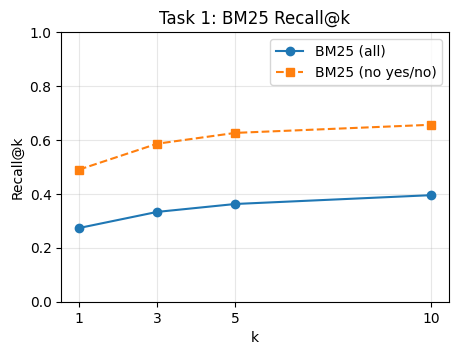

,question,gold,pred,variant,F1
0,What is polar bear's skin color?,white or cream,the world's largest land carnivores,the world's largest land carnivores,0.0
1,Is Canada a member of the OECD?,Yes.,the world's wealthiest nations,the world's wealthiest nations,0.0
2,Did Abraham Lincoln live in the Frontier?,Yes,the Abraham Lincoln Birthplace National Historic Site,the Abraham Lincoln Birthplace National Historic Site,0.0
3,When was Lee Kuan Yew prime minister of Singapore?,1959,its first Yang di-Pertuan Negara,its first Yang di-Pertuan Negara,0.0
4,What are the two subfamilies of the Native Ghanaian languages?,Kwa and Gur,the Niger-Congo language family,the Niger-Congo language family,0.0
5,What positions Ford played in the school football team?,Center and linebacker,Grand Rapids South High School,Grand Rapids South High School,0.0
6,Is the capital city Oslo?,no,the largest city,the largest city,0.0
7,Did Mainland Nova Scotia not come under British rule with the Treaty of Utre...,no!,the Seven Years' War,the Seven Years' War,0.0
8,What is the national language of Singapore?,The national language of Singapore is Malay.,The national language,the national anthem,0.5
9,Was John Calvin Coolidge Jr. was born in Las Vegas?,No,John Calvin Coolidge Jr.,the fourth of July,0.0


In [13]:
plt.figure(figsize=(5, 3.5))
plt.plot(KS, [task1_table.loc[0, f'R@{k}'] for k in KS], marker='o', label='BM25 (all)')
plt.plot(KS, [task1_table.loc[1, f'R@{k}'] for k in KS], marker='s', ls='--', label='BM25 (no yes/no)')
plt.xlabel('k'); plt.ylabel('Recall@k'); plt.title('Task 1: BM25 Recall@k')
plt.xticks(KS); plt.ylim(0, 1); plt.grid(alpha=.3); plt.legend()
plt.savefig(f'{OUT}/task1_recall.png', dpi=150, bbox_inches='tight'); plt.show()

# 10 random examples: question, gold, prediction, F1 (own seeded generator -> same sample on every run)
sample = random.Random(SEED).sample(range(len(questions)), min(10, len(questions)))
pd.set_option('display.max_colwidth', 80)
pd.DataFrame({'question': sub(questions, sample),
              'gold': sub(answers, sample),
              'pred': sub(task1_preds, sample),
              'variant': sub(variant_preds, sample),
              'F1':   [round(f1_score(task1_preds[i], answers[i]), 2) for i in sample]})

## 1.7 Saving the results
`task1_results.json` stores everything about Task 1:
- the top-100 BM25 ranking for every question (fused with the dense ranking in Task 3);
- the baseline and variant predictions;
- the metric tables;
- the dataset ids of the ranked passages;
- the configuration, including the dataset revision.

Tasks 2 and 3 use the same results directly from memory; the file is the permanent record.

In [14]:
if QUICK_TEST:
    print('QUICK_TEST is on - results NOT saved. Set QUICK_TEST = False and run all.')
else:
    with open(f'{OUT}/task1_results.json', 'w') as f:
        json.dump({'bm25_ranked': bm25_ranked,
                   'preds': task1_preds,                       # required baseline (used in Task 3)
                   'preds_variant': variant_preds,             # extra experiment (Section 1.5)
                   'metrics': task1_table.to_dict(orient='records'),
                   'metrics_variant': variant_table.to_dict(orient='records'),
                   'passage_ids': passage_ids,                 # dataset ids of the ranked positions
                   'config': {'k1': BM25_K1, 'b': BM25_B, 'top_k': TOP_K, 'keep_n': KEEP_N,
                              'dataset_revision': DATASET_REVISION}}, f)
    print('saved', f'{OUT}/task1_results.json')

saved Output_Final/task1_results.json


## 1.8 Discussion (Task 1)
*The numbers below are from the full run (`QUICK_TEST = False`) stored in `Output_Final/`.*

**Data.** The 918 questions are answered from 3,200 passages. 420 of them (45.8%) have a yes/no answer, including answers such as *"Yes, they do."*. The exact gold answer string occurs somewhere in the corpus for only 86.4% of the questions, and some gold answers are whole sentences of up to 58 words, which an extracted noun phrase can never match exactly.

**Retrieval.** BM25 ranks a passage containing the gold answer first for 27.3% of all questions, rising to 39.5% at k = 10. On the 498 non-yes/no questions, where answer-string recall is meaningful, recall is much higher:

| k | 1 | 3 | 5 | 10 |
|---|---|---|---|---|
| Recall@k (non-yes/no) | 49.0% | 58.6% | 62.7% | 65.7% |

Exact word matching therefore finds the evidence for about half of the factual questions. Recall keeps growing with k, so the right passage is often ranked between 2 and 10 rather than first.

**Answer extraction.** End-to-end scores are very low: EM 0.019 and F1 0.055 on all questions, and EM 0.034 and F1 0.099 on the non-yes/no questions. The error analysis shows that the bottleneck is the extraction rule rather than retrieval:
- the gold answer is inside the chosen sentence for 37.1% of the non-yes/no questions;
- but only 9.2% of those are answered exactly.

The "longest noun phrase" rule tends to pick a phrase that restates the question. Simply skipping such spans (Section 1.5) raises non-yes/no EM to 0.094 and F1 to 0.172. The extractive reader also cannot answer yes/no questions at all, which explains most of the gap between the "all" and "non-yes/no" rows.

**Limitations.** Recall@k is measured by answer-string matching, so short answers can match by accident and paraphrased answers are missed. EM also penalises formatting differences such as *"7"* vs *"seven"*.

**Conclusion.** A purely lexical pipeline retrieves useful evidence for roughly half of the factual questions, but the heuristic span extraction turns very little of it into exact answers. Better answer selection, rather than better retrieval, is the main room for improvement. This motivates the LLM reader in Task 2.

---
# Part 2 – Task 2: Paper Reproduction – Retrieval-Augmented Generation (RAG)

### Objective
Reproduce the retrieve-then-generate pipeline of Lewis et al., *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks* (NeurIPS 2020), on the same passage index as Task 1, and compare it with the classical baseline.

### Pipeline
1. **Dense retrieval:** `sentence-transformers/all-MiniLM-L6-v2` embeddings, FAISS flat index, cosine similarity, top-k = 5.
2. **Generation:** an open instruction-tuned LLM (`Qwen/Qwen2.5-1.5B-Instruct`) is prompted with the top-5 passages (each truncated to 200 tokens) and the question; at most 64 new tokens, temperature 0 (greedy decoding).
3. **Evaluation:** Exact Match, token F1 and Recall@k for k ∈ {1, 3, 5, 10}, computed with the same helpers as Task 1.

Task 2 needs a GPU for reasonable speed (about 5 minutes on a T4, most of it answer generation).

## 2.1 Dense retrieval
### 2.1.1 Encoding the passages and building the FAISS index
Each passage is turned into a 384-dimensional vector by MiniLM. We normalise every vector to length 1, so the inner product of two vectors equals their cosine similarity. FAISS `IndexFlatIP` performs exact ("flat", brute-force) inner-product search, which is therefore exact cosine search.

The index is built over the same `passages` list as BM25 in Task 1, with no re-chunking. MiniLM reads at most 256 word pieces per text, so the end of very long passages is ignored; the cell reports how many passages this affects.

In [15]:
import torch, faiss
from sentence_transformers import SentenceTransformer

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, '|', torch.cuda.get_device_name(0) if device == 'cuda' else 'no GPU (generation will be slow)')

encoder = SentenceTransformer(EMBED_MODEL, device=device)
t0 = time.time()
P_emb = encoder.encode(passages, batch_size=64, show_progress_bar=True,
                       normalize_embeddings=True).astype('float32')     # shape (N, 384)
print(f'encoded {P_emb.shape} in {time.time() - t0:.1f}s')

index = faiss.IndexFlatIP(P_emb.shape[1])     # flat = exact search, IP + unit vectors = cosine
index.add(P_emb)
print('FAISS index size:', index.ntotal)

# MiniLM only reads the first max_seq_length word pieces of each passage
n_long = sum(len(encoder.tokenizer(p, add_special_tokens=True)['input_ids']) > encoder.max_seq_length
             for p in passages)
print(f'max_seq_length = {encoder.max_seq_length}; passages longer than that (tail ignored): {n_long}')

device: cuda | Tesla T4


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (7 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/50 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (317 > 256). Running this sequence through the model will result in indexing errors


encoded (3200, 384) in 4.5s
FAISS index size: 3200
max_seq_length = 256; passages longer than that (tail ignored): 83


### 2.1.2 Retrieving passages for each question
Each question is encoded with the same model and compared with all 3,200 passage vectors. The LLM only receives the top 5; we keep the top 100 for Recall@10 and for the rank fusion in Task 3.

In [16]:
t0 = time.time()
Q_emb = encoder.encode(questions, batch_size=64, normalize_embeddings=True).astype('float32')
dense_scores, dense_ids = index.search(Q_emb, KEEP_N)            # best first
dense_ranked = [[int(p) for p in row] for row in dense_ids]
print(f'retrieval time: {time.time() - t0:.1f}s for {len(questions)} questions')

i = 0
print('Q:', questions[i], '| gold:', answers[i])
for rank, (pid, sc) in enumerate(zip(dense_ranked[i][:TOP_K], dense_scores[i][:TOP_K]), 1):
    print(rank, f'cos={sc:.3f}', passages[pid][:130].replace('\n', ' '), '...')

retrieval time: 0.3s for 918 questions
Q: Was Abraham Lincoln the sixteenth President of the United States? | gold: yes
1 cos=0.710 Young Abraham Lincoln ...
2 cos=0.582 Abraham Lincoln (February 12, 1809 – April 15, 1865) was the sixteenth President of the United States, serving from March 4, 1861  ...
3 cos=0.557 Sixteen months before his death, his son, John Quincy Adams, became the sixth President of the United States (1825 1829), the only ...
4 cos=0.557 * His earliest memory, from age 3, was of hearing that Abraham Lincoln had been elected and that a war was coming. ...
5 cos=0.550 On November 6, 1860, Lincoln was elected as the 16th President of the United States, beating Democrat Stephen A. Douglas, John C.  ...


## 2.2 Answer generation
### 2.2.1 Loading the LLM
We use `Qwen/Qwen2.5-1.5B-Instruct`. It is open (no login needed), instruction-tuned, and fits a free Colab T4 GPU in float16 (about 3 GB). Left padding is needed so that several prompts can be generated in one batch. The same model object is reused for the hybrid answers in Task 3.

In [17]:
from transformers import AutoTokenizer, AutoModelForCausalLM

tok = AutoTokenizer.from_pretrained(LLM_NAME)
tok.padding_side = 'left'                     # needed for batched generation
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
llm = AutoModelForCausalLM.from_pretrained(
    LLM_NAME, dtype=torch.float16 if device == 'cuda' else torch.float32,
    device_map='auto')
llm.eval()
print('loaded', LLM_NAME, '| parameters:', f'{llm.num_parameters() / 1e9:.2f}B')

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

loaded Qwen/Qwen2.5-1.5B-Instruct | parameters: 1.54B


### 2.2.2 Building the prompt
Each prompt contains a short system instruction, the top-5 passages numbered [1]–[5], and the question.

Passages are truncated with the LLM's own tokenizer, so "200 tokens" means 200 tokens as the generator sees them. The truncation never cuts a character in half, and each passage is truncated only once and then cached.

The instruction asks for a short answer, and for *yes* or *no* on yes/no questions, which make up about 46% of the dataset (see Section 0.4). We print one complete prompt to check what the model actually receives.

In [18]:
def truncate(text, max_tokens=PASSAGE_MAX_TOKENS):
    # first max_tokens LLM tokens of text; never ends in a half-cut character and re-encodes to <= max_tokens
    ids = tok(text, add_special_tokens=False)['input_ids'][:max_tokens]
    out = tok.decode(ids).rstrip('\ufffd')
    while len(tok(out, add_special_tokens=False)['input_ids']) > max_tokens:
        ids = ids[:-1]
        out = tok.decode(ids).rstrip('\ufffd')
    return out

@lru_cache(maxsize=None)
def passage_text(pid):
    return truncate(passages[pid])           # each passage is cut only once, however often it is retrieved

SYSTEM = ('You answer questions using ONLY the given passages. '
          'Reply with a short answer of a few words. No explanation. '
          'If it is a yes/no question, reply yes or no.')

def build_prompt(question, passage_ids):
    context = '\n\n'.join(f'[{j+1}] {passage_text(p)}'
                           for j, p in enumerate(passage_ids))
    messages = [{'role': 'system', 'content': SYSTEM},
                {'role': 'user',
                 'content': f'Passages:\n{context}\n\nQuestion: {question}\nShort answer:'}]
    return tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

example_prompt = build_prompt(questions[0], dense_ranked[0][:TOP_K])
print(example_prompt[:1500], '...')                      # always read one prompt!
print('\nprompt length:', len(tok(example_prompt, add_special_tokens=False)['input_ids']), 'tokens')

<|im_start|>system
You answer questions using ONLY the given passages. Reply with a short answer of a few words. No explanation. If it is a yes/no question, reply yes or no.<|im_end|>
<|im_start|>user
Passages:
[1] Young Abraham Lincoln

[2] Abraham Lincoln (February 12, 1809 – April 15, 1865) was the sixteenth President of the United States, serving from March 4, 1861 until his assassination. As an outspoken opponent of the expansion of slavery in the United States, "[I]n his short autobiography written for the 1860 presidential campaign, Lincoln would describe his protest in the Illinois legislature as one that 'briefly defined his position on the slavery question, and so far as it goes, it was then the same that it is now." This was in reference to the anti-expansion sentiments he had then expressed. Doris Kearns Goodwin, Team of Rivals: The Political Genius of Abraham Lincoln (2005) p. 91.  Holzer pg. 232.  Writing of the Cooper Union  speech, Holzer notes, "Cooper Union proved a u

### 2.2.3 Generating the answers
- **Temperature 0** means always choosing the most likely next token, i.e. greedy decoding (`do_sample=False`). Qwen's default generation settings add sampling parameters and a repetition penalty of 1.05; we override them so that decoding is purely greedy, as the brief requires.
- The prompt already contains the model's special tokens, so none are added again during tokenisation.
- We keep only the first line of the generated text as the answer.
- Answers are saved to a cache file every 10 batches. If the Colab session disconnects, re-running the cell resumes where it stopped. The cache stores a fingerprint of all settings (model, prompt, top-k, token limits, batch size, rankings), so answers made with different settings are never reused. `RESET_CACHE = True` (Section 0.1) forces a fresh run.

`rag_answer_all` is defined once here and reused for the hybrid ranking in Task 3, so the generation code of the two tasks is identical.

In [19]:
@torch.no_grad()
def generate_batch(prompts):
    # the chat template already holds any special tokens, so none are added here (no double BOS)
    enc = tok(prompts, return_tensors='pt', padding=True, add_special_tokens=False).to(llm.device)
    out = llm.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                       temperature=None, top_p=None, top_k=None, repetition_penalty=1.0,
                       pad_token_id=tok.pad_token_id)
    new_tokens = out[:, enc['input_ids'].shape[1]:]          # drop the prompt part
    texts = tok.batch_decode(new_tokens, skip_special_tokens=True)
    return [t.strip().split('\n')[0].strip() for t in texts]  # keep first line only

def settings_fingerprint(ranked_lists, k, batch_size):
    # everything that determines the answers; a cache made with other settings is not reused
    key = json.dumps([LLM_NAME, SYSTEM, k, PASSAGE_MAX_TOKENS, MAX_NEW_TOKENS, batch_size,
                      DATASET_REVISION, questions, [r[:k] for r in ranked_lists]])
    return hashlib.sha256(key.encode()).hexdigest()

def save_json_atomic(obj, path):
    # write to a temporary file first, so an interrupted write never leaves a broken cache
    with open(path + '.tmp', 'w') as f:
        json.dump(obj, f)
    os.replace(path + '.tmp', path)

def rag_answer_all(ranked_lists, k=TOP_K, batch_size=BATCH_SIZE, cache_file=None):
    fingerprint = settings_fingerprint(ranked_lists, k, batch_size)
    preds = []
    if cache_file and os.path.exists(cache_file) and not RESET_CACHE:
        try:
            cached = json.load(open(cache_file))
        except json.JSONDecodeError:
            cached = None
        if isinstance(cached, dict) and cached.get('fingerprint') == fingerprint:
            preds = cached['preds'][:len(questions)]
            print(f'resuming: {len(preds)} answers already in {cache_file}')
        else:
            print('cache was made with other settings (or is damaged) - generating from scratch')
    for n, s in enumerate(tqdm(range(len(preds), len(questions), batch_size), desc='generating')):
        batch = [build_prompt(questions[i], ranked_lists[i][:k])
                 for i in range(s, min(s + batch_size, len(questions)))]
        preds += generate_batch(batch)
        if cache_file and n % 10 == 9:
            save_json_atomic({'fingerprint': fingerprint, 'preds': preds}, cache_file)
    if cache_file:
        save_json_atomic({'fingerprint': fingerprint, 'preds': preds}, cache_file)
    return preds

task2_cache_file = f'{OUT}/task2_generation_cache{"_quick" if QUICK_TEST else ""}.json'
t0 = time.time()
task2_preds = rag_answer_all(dense_ranked, k=TOP_K, cache_file=task2_cache_file)
print(f'generation time: {time.time() - t0:.0f}s')
for q, gold, p in list(zip(questions, answers, task2_preds))[:5]:
    print(f'Q: {q}\n   gold: {gold} | pred: {p}')

generating:   0%|          | 0/115 [00:00<?, ?it/s]

generation time: 170s
Q: Was Abraham Lincoln the sixteenth President of the United States?
   gold: yes | pred: yes
Q: Did Lincoln sign the National Banking Act of 1863?
   gold: yes | pred: yes
Q: Did his mother die of pneumonia?
   gold: no | pred: no
Q: How many long was Lincoln's formal education?
   gold: 18 months | pred: 18 months
Q: When did Lincoln begin his political career?
   gold: 1832 | pred: 1832


## 2.3 Evaluation
We report three rows:
- **all 918 questions:** the official numbers;
- **the 498 non-yes/no questions:** where answer-string Recall@k is meaningful;
- **the 420 yes/no questions:** whose gold answer starts with yes or no, e.g. *"Yes, they do."*. Recall@k is not meaningful for this row.

In [20]:
task2_table = pd.DataFrame([
    evaluate(task2_preds, dense_ranked, answers, 'Task 2 Dense+LLM (all)'),
    evaluate(sub(task2_preds, keep), sub(dense_ranked, keep), sub(answers, keep),
             'Task 2 Dense+LLM (no yes/no)'),
    evaluate(sub(task2_preds, yesno), sub(dense_ranked, yesno), sub(answers, yesno),
             'Task 2 Dense+LLM (yes/no only)'),
]).round(4)
task2_table

,System,N,EM,F1,R@1,R@3,R@5,R@10
0,Task 2 Dense+LLM (all),918,0.5643,0.6710,0.2266,0.3061,0.3442,0.3802
1,Task 2 Dense+LLM (no yes/no),498,0.3133,0.5049,0.3996,0.5382,0.6004,0.6446
2,Task 2 Dense+LLM (yes/no only),420,0.8619,0.8681,0.0214,0.0310,0.0405,0.0667


## 2.4 Error analysis: retrieval vs. generation
We check two things:
- whether the predictions are as short as the gold answers, since long answers hurt EM;
- for the non-yes/no questions, how often the answer is correct (F1 ≥ 0.5) when the gold answer string **is** and **is not** found in the top-5 passages.

**Reading the second row:** "gold NOT in top-5" only means that the gold answer does not appear *word for word* in the top-5 passages. A correct answer in that row is usually a **paraphrase** of a long gold answer (e.g. *"13 species in 7 genera"* vs *"13 species and 7 genera"*). It therefore mostly reflects a limitation of answer-string Recall@k, not proof that the LLM answered from its own memory. Whether answers are supported by the retrieved passages is tested properly in Task 3.

In [21]:
pred_len = np.mean([len(normalize_answer(p).split()) for p in task2_preds])
gold_len = np.mean([len(normalize_answer(a).split()) for a in answers])
print(f'average answer length (words): pred {pred_len:.2f} | gold {gold_len:.2f}')

in_top5 = np.array([first_hit_rank(dense_ranked[i][:TOP_K], answers[i]) <= TOP_K for i in keep])
correct = np.array([f1_score(task2_preds[i], answers[i]) >= 0.5 for i in keep])
task2_diag = pd.DataFrame({
    'questions': [in_top5.sum(), (~in_top5).sum()],
    'correct (F1>=0.5)': [correct[in_top5].sum(), correct[~in_top5].sum()],
    'accuracy': [correct[in_top5].mean(), correct[~in_top5].mean()],
}, index=['gold in top-5 passages', 'gold NOT in top-5 passages']).round(4)
task2_diag

average answer length (words): pred 2.20 | gold 3.16


,questions,correct (F1>=0.5),accuracy
gold in top-5 passages,299,215,0.7191
gold NOT in top-5 passages,199,48,0.2412


## 2.5 Comparison with Task 1
Same questions, same passages and same metric code: only the retriever (BM25 → dense) and the reader (extractive → LLM) change. The Task 1 rankings and answers come straight from Part 1.

In [22]:
compare_t1_t2 = pd.DataFrame([
    evaluate(task1_preds, bm25_ranked, answers, 'Task 1: BM25 + extractive'),
    evaluate(task2_preds, dense_ranked, answers, 'Task 2: Dense + LLM'),
    evaluate(sub(task1_preds, keep), sub(bm25_ranked, keep), sub(answers, keep),
             'Task 1: BM25 + extractive (no yes/no)'),
    evaluate(sub(task2_preds, keep), sub(dense_ranked, keep), sub(answers, keep),
             'Task 2: Dense + LLM (no yes/no)'),
]).round(4)
compare_t1_t2

,System,N,EM,F1,R@1,R@3,R@5,R@10
0,Task 1: BM25 + extractive,918,0.0185,0.0553,0.2734,0.3333,0.3627,0.3954
1,Task 2: Dense + LLM,918,0.5643,0.6710,0.2266,0.3061,0.3442,0.3802
2,Task 1: BM25 + extractive (no yes/no),498,0.0341,0.0991,0.4900,0.5863,0.6265,0.6566
3,Task 2: Dense + LLM (no yes/no),498,0.3133,0.5049,0.3996,0.5382,0.6004,0.6446


## 2.6 Additional checks
A few numbers we use in the discussion:
1. yes/no accuracy compared with always answering "yes";
2. whether correct answers without the gold string in the top-5 are paraphrases;
3. how often a very short, caption-like passage is ranked first;
4. how much BM25 and dense retrieval complement each other.

In [23]:
# 1) yes/no questions
yn_acc = np.mean([first_word(task2_preds[i]) == first_word(answers[i]) for i in yesno])   # yes vs no agrees
always_yes = np.mean([first_word(answers[i]) == ['yes'] for i in yesno])
gold_no = [i for i in yesno if first_word(answers[i]) == ['no']]
said_yes = sum(first_word(task2_preds[i]) == ['yes'] for i in gold_no)
print(f'1) yes/no accuracy {yn_acc:.3f} vs always-"yes" baseline {always_yes:.3f}; '
      f'gold "no" answered "yes": {said_yes}/{len(gold_no)}')
print(f'   factual (non-yes/no) questions answered with yes/no: '
      f'{sum(normalize_answer(task2_preds[i]) in ("yes", "no") for i in keep)}/{len(keep)}')

# 2) correct answers whose gold string is not in the top-5: does the string exist anywhere?
no_ev = [i for i in keep if f1_score(task2_preds[i], answers[i]) >= 0.5 and
         first_hit_rank(dense_ranked[i][:TOP_K], answers[i]) > TOP_K]
anywhere = sum(any(f' {normalize_answer(answers[i])} ' in p for p in norm_passages) for i in no_ev)
print(f'2) correct but gold string not in top-5: {len(no_ev)}; '
      f'gold string occurs anywhere in the corpus for only {anywhere} of them')

# 3) very short (caption-like) passages ranked first by the dense retriever
print(f'3) dense top-1 passage has <= 5 words for {sum(len(passages[r[0]].split()) <= 5 for r in dense_ranked)} '
      f'questions (corpus has {sum(len(p.split()) <= 5 for p in passages)} such passages)')

# 4) BM25 vs dense complementarity (motivates Task 3)
b5 = lambda i: first_hit_rank(bm25_ranked[i][:TOP_K], answers[i]) <= TOP_K
d5 = lambda i: first_hit_rank(dense_ranked[i][:TOP_K], answers[i]) <= TOP_K
overlap = np.mean([len(set(bm25_ranked[i][:TOP_K]) & set(dense_ranked[i][:TOP_K])) / TOP_K
                   for i in range(len(questions))])
print(f'4) BM25/dense top-5 overlap {overlap:.3f}; non-yes/no answers found only by BM25: '
      f'{sum(b5(i) and not d5(i) for i in keep)}, only by dense: {sum(d5(i) and not b5(i) for i in keep)}')

1) yes/no accuracy 0.879 vs always-"yes" baseline 0.810; gold "no" answered "yes": 24/80
   factual (non-yes/no) questions answered with yes/no: 20/498
2) correct but gold string not in top-5: 48; gold string occurs anywhere in the corpus for only 9 of them
3) dense top-1 passage has <= 5 words for 93 questions (corpus has 231 such passages)
4) BM25/dense top-5 overlap 0.340; non-yes/no answers found only by BM25: 40, only by dense: 27


## 2.7 Recall@k plot and example predictions
The plot compares dense Recall@k with BM25 from Task 1. The table lists ten randomly chosen questions with their predictions and F1.

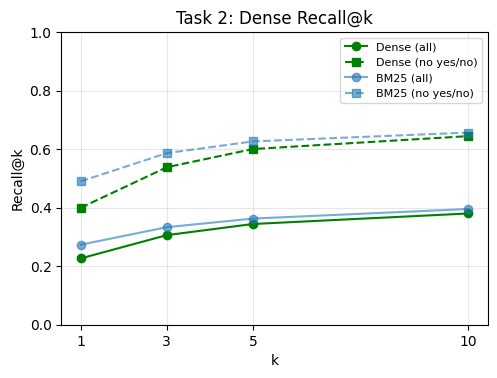

,question,gold,pred,F1
0,What is polar bear's skin color?,white or cream,Black,0.00
1,Is Canada a member of the OECD?,Yes.,Yes,1.00
2,Did Abraham Lincoln live in the Frontier?,Yes,Yes,1.00
3,When was Lee Kuan Yew prime minister of Singapore?,1959,1959 to 1990,0.50
4,What are the two subfamilies of the Native Ghanaian languages?,Kwa and Gur,Kwa and Gur,1.00
5,What positions Ford played in the school football team?,Center and linebacker,center and linebacker,1.00
6,Is the capital city Oslo?,no,No,1.00
7,Did Mainland Nova Scotia not come under British rule with the Treaty of Utre...,no!,yes,0.00
8,What is the national language of Singapore?,The national language of Singapore is Malay.,Malay,0.29
9,Was John Calvin Coolidge Jr. was born in Las Vegas?,No,No,1.00


In [24]:
plt.figure(figsize=(5.5, 3.8))
plt.plot(KS, [recall_at_k(dense_ranked, answers, k) for k in KS], marker='o', color='green',
         label='Dense (all)')
plt.plot(KS, [recall_at_k(sub(dense_ranked, keep), sub(answers, keep), k) for k in KS],
         marker='s', ls='--', color='green', label='Dense (no yes/no)')
plt.plot(KS, [recall_at_k(bm25_ranked, answers, k) for k in KS], marker='o',
         color='tab:blue', alpha=.6, label='BM25 (all)')
plt.plot(KS, [recall_at_k(sub(bm25_ranked, keep), sub(answers, keep), k) for k in KS],
         marker='s', ls='--', color='tab:blue', alpha=.6, label='BM25 (no yes/no)')
plt.xlabel('k'); plt.ylabel('Recall@k'); plt.title('Task 2: Dense Recall@k')
plt.xticks(KS); plt.ylim(0, 1); plt.grid(alpha=.3); plt.legend(fontsize=8)
plt.savefig(f'{OUT}/task2_recall.png', dpi=150, bbox_inches='tight'); plt.show()

sample = random.Random(SEED).sample(range(len(questions)), min(10, len(questions)))
pd.set_option('display.max_colwidth', 80)
pd.DataFrame({'question': sub(questions, sample), 'gold': sub(answers, sample),
              'pred': sub(task2_preds, sample),
              'F1': [round(f1_score(task2_preds[i], answers[i]), 2) for i in sample]})

## 2.8 Saving the results
`task2_results.json` contains:
- the dense top-100 ranking for every question;
- the generated answers and the metric table;
- the dataset ids of the ranked passages;
- the generation settings (model, system prompt, token limits, batch size, dataset revision).

Task 3 generates its hybrid answers with exactly these settings, so only the retriever changes.

In [25]:
if QUICK_TEST:
    print('QUICK_TEST is on - results NOT saved. Set QUICK_TEST = False and run all.')
else:
    with open(f'{OUT}/task2_results.json', 'w') as f:
        json.dump({'dense_ranked': dense_ranked,
                   'preds': task2_preds,
                   'llm': LLM_NAME,
                   'metrics': task2_table.to_dict(orient='records'),
                   'passage_ids': passage_ids,           # dataset ids of the ranked positions
                   'config': {'embed_model': EMBED_MODEL, 'top_k': TOP_K,
                              'passage_max_tokens': PASSAGE_MAX_TOKENS,
                              'max_new_tokens': MAX_NEW_TOKENS, 'decoding': 'greedy',
                              'batch_size': BATCH_SIZE, 'dataset_revision': DATASET_REVISION,
                              'system_prompt': SYSTEM, 'keep_n': KEEP_N}}, f)
    print('saved', f'{OUT}/task2_results.json')

saved Output_Final/task2_results.json


## 2.9 Discussion (Task 2)
*The numbers below are from the full run (`QUICK_TEST = False`) stored in `Output_Final/`.*

**Overall.** Dense retrieval combined with `Qwen2.5-1.5B-Instruct` reaches **EM 0.564 and F1 0.671** on all 918 questions, compared with EM 0.019 and F1 0.055 for the Task 1 baseline. On the 498 non-yes/no questions it reaches EM 0.313 and F1 0.505 (Task 1: 0.034 and 0.099). Both tasks use identical text cleaning and metric code, so these numbers are directly comparable.

**Retrieval did not improve.** On the non-yes/no questions, MiniLM's answer-string recall is *below* BM25 at every k:

| | R@1 | R@3 | R@5 | R@10 |
|---|---|---|---|---|
| BM25 (Task 1) | 0.490 | 0.586 | 0.627 | 0.657 |
| Dense (Task 2) | 0.400 | 0.538 | 0.600 | 0.645 |

Many questions name specific entities (people, places, dates), which exact word matching handles well. MiniLM also tends to rank very short, caption-like passages first (e.g. *"Young Abraham Lincoln"*, for 93 questions), and it only reads the first 256 word pieces of the 83 longest passages.

The two retrievers are, however, **complementary**: their top-5 lists share only about 34% of their passages. BM25 finds the answer for 40 factual questions that dense retrieval misses, while dense retrieval finds 27 that BM25 misses. This is what Task 3 builds on.

**The gain comes from the reader.** When the gold answer is in the top-5 passages, the LLM answers correctly (F1 ≥ 0.5) for 71.9% of the questions (215 of 299). Its answers are short (2.2 words on average vs 3.2 for the gold answers), so EM is meaningful. F1 > EM mostly reflects partial matches such as *"1959 to 1990"* vs *"1959"*, or *"Malay"* vs a full-sentence gold answer. Unlike the extractive reader, it can also answer yes/no questions.

**Yes/no questions.**
- The model gives the right yes/no answer for 87.9% of the 420 yes/no questions. EM is 0.862 because 10 gold answers are full sentences such as *"Yes, they do."*.
- Answering "yes" every time would already score 81.0%, so the real gain is modest.
- The model says "yes" to 24 of the 80 questions whose answer is "no".
- The yes/no instruction in the prompt also leaks into 20 factual questions that were answered "yes" or "no".

**Limitations.** EM penalises formatting (*"7"* vs *"seven"*), and some gold labels in the dataset are noisy. The 48 answers that are correct although the gold string is not in the top-5 passages are mostly paraphrases: the exact gold string occurs nowhere in the corpus for 39 of them. They reflect a limitation of answer-string Recall@k rather than the model answering from memory. Whether the generated answers are really supported by the retrieved passages is measured by the groundedness check in Task 3.

**Conclusion.** Replacing the extractive reader with an LLM raises EM about 30 times and F1 about 12 times over the baseline, even though the dense retriever is weaker than BM25 on this dataset. The generator, not the retriever, makes the difference. The complementary strengths of the two retrievers suggest combining them, which we do in Task 3.

---
# Part 3 – Task 3: Combine & Improve – Hybrid Retrieval with Groundedness Verification

### Objective
Combine the two retrieval signals of Tasks 1 and 2 into one retriever, and reuse Task 1's lexical-overlap idea to check whether Task 2's generated answers are supported by the retrieved evidence.

### What this part does
1. **Hybrid retrieval:** fuse the BM25 ranking (Task 1) and the dense ranking (Task 2) with **Reciprocal Rank Fusion** (constant 60), then answer with the **same LLM, prompt and decoding as Task 2** using the hybrid top-5.
2. **Groundedness check:** compute the lexical overlap between each Task 2 answer and the passages it was generated from, and flag (or abstain on) low-overlap answers as likely ungrounded.
3. **Evaluation:** EM, F1 and Recall@k of the hybrid system vs. Task 1 and Task 2, the fraction of correct answers with high overlap and of incorrect answers with low overlap, and the accuracy of the groundedness check.

`bm25_ranked`, `task1_preds`, `dense_ranked` and `task2_preds` come from Parts 1 and 2, and the LLM, tokenizer and generation code (`rag_answer_all`, `passage_text`) are the objects already loaded in Part 2. So the generation settings are guaranteed to be identical to Task 2's.

## 3.1 Hybrid retrieval with Reciprocal Rank Fusion
Every passage receives **1 / (60 + rank)** from each ranked list it appears in (ranks start at 1), and the two contributions are added. A passage that is ranked well by *both* retrievers rises to the top. A passage missing from one list simply gets nothing from it.

RRF only uses ranks, so BM25 scores and cosine similarities never have to be put on a common scale. The small example in the cell shows the arithmetic.

In [26]:
def rrf(rank_lists, c=RRF_C, top_n=KEEP_N):
    score = collections.defaultdict(float)
    for ranking in rank_lists:
        for rank, pid in enumerate(ranking, start=1):
            score[pid] += 1.0 / (c + rank)
    fused = sorted(score.items(), key=lambda x: x[1], reverse=True)   # ties keep BM25 order
    return [pid for pid, _ in fused[:top_n]]

hybrid_ranked = [rrf([b, d]) for b, d in zip(bm25_ranked, dense_ranked)]

# Tiny worked example: passage 7 is #1 for BM25 and #3 for dense -> 1/61 + 1/63 = 0.0323,
# which beats passage 9 that is #1 for dense only (1/61 = 0.0164 + 0 from BM25)
print(rrf([[7, 2, 4], [9, 4, 7]], top_n=5))     # -> [7, 4, 9, 2]

i = 0
print('Q:', questions[i], '| gold:', answers[i])
print('BM25  top-5:', bm25_ranked[i][:TOP_K])
print('Dense top-5:', dense_ranked[i][:TOP_K])
print('RRF   top-5:', hybrid_ranked[i][:TOP_K])

[7, 4, 9, 2]
Q: Was Abraham Lincoln the sixteenth President of the United States? | gold: yes
BM25  top-5: [278, 322, 374, 353, 1991]
Dense top-5: [288, 278, 697, 2227, 319]
RRF   top-5: [278, 319, 697, 1812, 371]


## 3.2 Answering with the hybrid top-5
We generate one answer per question from the hybrid top-5 with `rag_answer_all` from Section 2.2.3: the same model, prompt construction, 200-token truncation, greedy decoding, batch size and answer cache as in Task 2. The only thing that changes is the ranking the passages come from, so any difference in EM/F1 between Task 2 and Task 3 is caused by retrieval. As in Task 2, the answers are cached with a settings fingerprint, so an interrupted run resumes and an outdated cache is never reused.

In [27]:
task3_cache_file = f'{OUT}/task3_hybrid_generation_cache{"_quick" if QUICK_TEST else ""}.json'
t0 = time.time()
hybrid_preds = rag_answer_all(hybrid_ranked, k=TOP_K, cache_file=task3_cache_file)
print(f'generation time: {time.time() - t0:.0f}s')
for q, gold, a2, a3 in list(zip(questions, answers, task2_preds, hybrid_preds))[:5]:
    print(f'Q: {q}\n   gold: {gold} | Task 2: {a2} | hybrid: {a3}')

generating:   0%|          | 0/115 [00:00<?, ?it/s]

generation time: 210s
Q: Was Abraham Lincoln the sixteenth President of the United States?
   gold: yes | Task 2: yes | hybrid: yes
Q: Did Lincoln sign the National Banking Act of 1863?
   gold: yes | Task 2: yes | hybrid: yes
Q: Did his mother die of pneumonia?
   gold: no | Task 2: no | hybrid: yes
Q: How many long was Lincoln's formal education?
   gold: 18 months | Task 2: 18 months | hybrid: 18 months
Q: When did Lincoln begin his political career?
   gold: 1832 | Task 2: 1832 | hybrid: 1832


## 3.3 Comparison: Task 1 vs. Task 2 vs. Task 3
We report EM, F1 and Recall@k for the three systems on all questions (official numbers) and on the 498 non-yes/no questions, where answer-string recall is meaningful. For the 420 yes/no questions we report yes/no accuracy instead. The second cell plots Recall@k for the three retrievers.

In [28]:
systems = [('Task 1: BM25 + extractive',  task1_preds,  bm25_ranked),
           ('Task 2: Dense + LLM',        task2_preds,  dense_ranked),
           ('Task 3: Hybrid (RRF) + LLM', hybrid_preds, hybrid_ranked)]

compare_all = pd.DataFrame([evaluate(p, r, answers, name) for name, p, r in systems]).round(4)
compare_fact = pd.DataFrame([evaluate(sub(p, keep), sub(r, keep), sub(answers, keep), name + ' (no yes/no)')
                             for name, p, r in systems]).round(4)
yesno_acc = pd.DataFrame([{'System': name, 'yes/no accuracy': np.mean([first_word(p[i]) == first_word(answers[i]) for i in yesno])}
                          for name, p, _ in systems]).round(4)
print('All questions'); display(compare_all)
print('Non-yes/no questions'); display(compare_fact)
print('Yes/no questions (Recall@k not meaningful here)'); display(yesno_acc)

All questions


,System,N,EM,F1,R@1,R@3,R@5,R@10
0,Task 1: BM25 + extractive,918,0.0185,0.0553,0.2734,0.3333,0.3627,0.3954
1,Task 2: Dense + LLM,918,0.5643,0.6710,0.2266,0.3061,0.3442,0.3802
2,Task 3: Hybrid (RRF) + LLM,918,0.5719,0.6836,0.2723,0.3420,0.3682,0.4041


Non-yes/no questions


,System,N,EM,F1,R@1,R@3,R@5,R@10
0,Task 1: BM25 + extractive (no yes/no),498,0.0341,0.0991,0.4900,0.5863,0.6265,0.6566
1,Task 2: Dense + LLM (no yes/no),498,0.3133,0.5049,0.3996,0.5382,0.6004,0.6446
2,Task 3: Hybrid (RRF) + LLM (no yes/no),498,0.3414,0.5411,0.4839,0.6004,0.6365,0.6787


Yes/no questions (Recall@k not meaningful here)


,System,yes/no accuracy
0,Task 1: BM25 + extractive,0.0024
1,Task 2: Dense + LLM,0.8786
2,Task 3: Hybrid (RRF) + LLM,0.8643


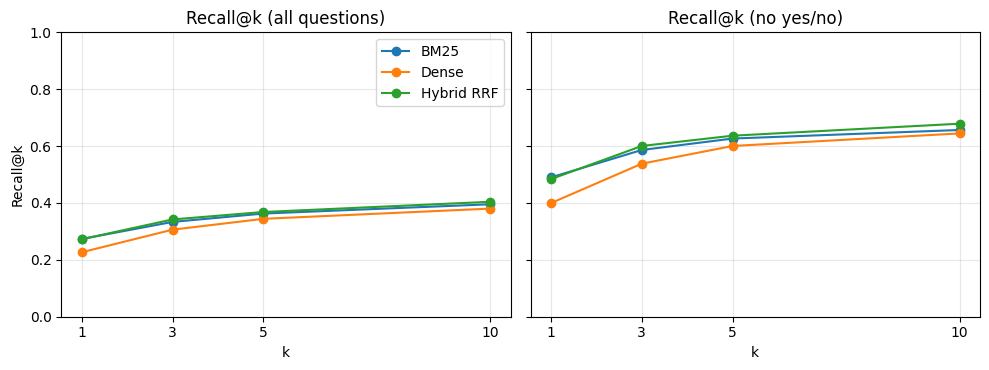

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, (title, idx) in zip(axes, [('all questions', range(len(questions))), ('no yes/no', keep)]):
    for name, ranked in [('BM25', bm25_ranked), ('Dense', dense_ranked), ('Hybrid RRF', hybrid_ranked)]:
        ax.plot(KS, [recall_at_k(sub(ranked, idx), sub(answers, idx), k) for k in KS], marker='o', label=name)
    ax.set_title(f'Recall@k ({title})'); ax.set_xlabel('k'); ax.set_xticks(KS); ax.grid(alpha=.3)
axes[0].set_ylabel('Recall@k'); axes[0].set_ylim(0, 1); axes[0].legend()
plt.tight_layout()
plt.savefig(f'{OUT}/task3_recall_compare.png', dpi=150, bbox_inches='tight'); plt.show()

## 3.4 Groundedness check
### 3.4.1 Lexical overlap between an answer and its passages
For each Task 2 answer we take its content words (words that are not stop-words) and measure what fraction of them appears in each of the five passages it was generated from. We use exactly the 200-token text the LLM saw. The best passage gives the score:
- overlap = 1.0: every content word of the answer occurs in one retrieved passage (well supported);
- overlap = 0.0: none of its words occur in the evidence (possibly produced from the model's own knowledge).

**Answers that are just "yes" or "no" are excluded** from the check, and never abstained on, because these words almost never appear in passages. We decide this from the *prediction*, not the gold answer, because at answer time the system only knows its own output.

`ground` holds all Task 2 answers; `checked` holds the non-yes/no answers the check is applied to.

In [30]:
def overlap_score(answer, passage_texts):
    a = content_words(answer) or set(normalize_answer(answer).split())
    if not a:
        return 0.0
    return max(len(a & set(normalize_answer(p).split())) / len(a) for p in passage_texts)

def groundedness_frame(preds, ranked):
    rows = []
    for i, (p, ids) in enumerate(zip(preds, ranked)):
        seen = [passage_text(pid) for pid in ids[:TOP_K]]   # the 200-token text the LLM saw (cached)
        rows.append({'question': questions[i], 'gold': answers[i], 'pred': p,
                     'overlap': overlap_score(p, seen),
                     'F1': f1_score(p, answers[i]), 'EM': exact_match(p, answers[i]),
                     'yes_no': is_yes_no_prediction(p)})      # yes/no PREDICTION -> not checked
    df = pd.DataFrame(rows)
    df['correct'] = df['F1'] >= CORRECT_F1
    return df

ground = groundedness_frame(task2_preds, dense_ranked)
checked = ground[~ground['yes_no']].copy()       # the check is applied to these answers
checked['grounded'] = checked['overlap'] >= THRESH
print(f'answers checked: {len(checked)} | excluded yes/no answers: {int(ground.yes_no.sum())} '
      f'(of which {int((ground.yes_no & ~ground.gold.map(is_yes_no)).sum())} answer a factual question)')
checked.head()

answers checked: 481 | excluded yes/no answers: 437 (of which 20 answer a factual question)


,question,gold,pred,overlap,F1,EM,yes_no,correct,grounded
3,How many long was Lincoln's formal education?,18 months,18 months,1.0,1.000000,1.0,False,True,True
4,When did Lincoln begin his political career?,1832,1832,1.0,1.000000,1.0,False,True,True
5,What did The Legal Tender Act of 1862 establish?,"the United States Note, the first paper currency in United States history",United States Note,1.0,0.461538,0.0,False,False,True
6,Who suggested Lincoln grow a beard?,11-year-old Grace Bedell,Grace Bedell,1.0,0.800000,0.0,False,True,True
7,When did the Gettysburg address argue that America was born?,1776,1776,1.0,1.000000,1.0,False,True,True


### 3.4.2 How well does the check work?
We treat the check as a classifier: a high overlap predicts "correct", and a low overlap predicts "likely ungrounded or wrong" (flagged). We report:
- **correct answers with high overlap:** how often good answers pass the check;
- **incorrect answers with low overlap:** how often bad answers are caught;
- **groundedness-check accuracy:** the fraction of answers where the check agrees with correctness;
- **balanced accuracy:** the average of the first two, which is fairer when correct and incorrect answers are unbalanced;
- **majority baseline:** the accuracy of a check that never flags anything.

We also show the 2×2 table and a histogram of the overlap scores.

In [31]:
def check_report(df, name, thresh=THRESH, label='correct'):
    grounded = df['overlap'] >= thresh
    ok = df[label].astype(bool)
    hi_correct = grounded[ok].mean()                 # correct answers WITH high overlap
    lo_wrong   = (~grounded[~ok]).mean()             # incorrect answers WITH low overlap
    return {'Answers': name, 'N': len(df), 'correct': int(ok.sum()), 'flagged': int((~grounded).sum()),
            'correct w/ high overlap': hi_correct, 'incorrect w/ low overlap': lo_wrong,
            'check accuracy': (grounded == ok).mean(),
            'balanced accuracy': (hi_correct + lo_wrong) / 2,
            'majority baseline': max(ok.mean(), 1 - ok.mean())}

ground_table = pd.DataFrame([
    check_report(checked, 'Task 2 answers (correct = F1 >= 0.5)'),
    check_report(checked.assign(correct_em=checked['EM'] == 1), 'Task 2 answers (correct = EM)',
                 label='correct_em'),
]).round(4)
display(ground_table)

# 2x2 table for the report
pd.crosstab(checked['correct'].map({True: 'correct', False: 'incorrect'}),
            checked['grounded'].map({True: 'high overlap', False: 'low overlap (flagged)'}), margins=True)

,Answers,N,correct,flagged,correct w/ high overlap,incorrect w/ low overlap,check accuracy,balanced accuracy,majority baseline
0,Task 2 answers (correct = F1 >= 0.5),481,263,35,0.9886,0.1468,0.6071,0.5677,0.5468
1,Task 2 answers (correct = EM),481,156,35,0.9872,0.1015,0.3888,0.5444,0.6757


grounded,high overlap,low overlap (flagged),All
correct,,,
correct,260,3,263
incorrect,186,32,218
All,446,35,481


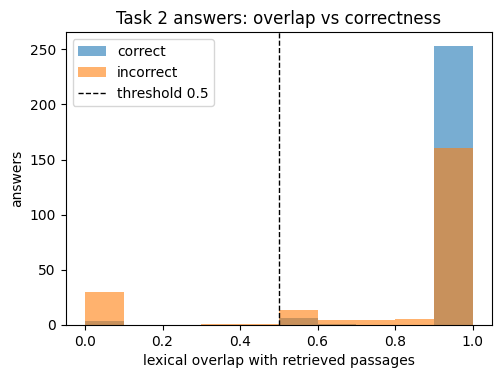

In [32]:
# Overlap distribution for correct vs incorrect answers
plt.figure(figsize=(5.5, 3.8))
bins = np.linspace(0, 1, 11)
plt.hist(checked.loc[checked.correct, 'overlap'], bins=bins, alpha=.6, label='correct')
plt.hist(checked.loc[~checked.correct, 'overlap'], bins=bins, alpha=.6, label='incorrect')
plt.axvline(THRESH, color='k', ls='--', lw=1, label=f'threshold {THRESH}')
plt.xlabel('lexical overlap with retrieved passages'); plt.ylabel('answers')
plt.title('Task 2 answers: overlap vs correctness'); plt.legend()
plt.savefig(f'{OUT}/task3_overlap_hist.png', dpi=150, bbox_inches='tight'); plt.show()

### 3.4.3 Abstaining on flagged answers, and the threshold sweep
To **abstain** means to answer *"I don't know"* instead of giving a flagged answer. A higher threshold keeps fewer answers (lower **coverage**), but the answers that are kept should be correct more often. In the "all questions" columns an abstention counts as wrong; yes/no predictions are never flagged.

,threshold,coverage,F1 on answered,check accuracy,EM all questions,F1 all questions
0,0.0,1.0000,0.5227,0.5468,0.5643,0.6710
1,0.1,0.9314,0.5556,0.6029,0.5621,0.6683
2,0.2,0.9314,0.5556,0.6029,0.5621,0.6683
3,0.3,0.9314,0.5556,0.6029,0.5621,0.6683
4,0.4,0.9293,0.5561,0.6050,0.5621,0.6680
5,0.5,0.9272,0.5574,0.6071,0.5621,0.6680
6,0.6,0.8898,0.5684,0.6195,0.5599,0.6621
7,0.7,0.8773,0.5742,0.6279,0.5599,0.6611
8,0.8,0.8690,0.5785,0.6362,0.5599,0.6606
9,0.9,0.8586,0.5835,0.6466,0.5599,0.6597


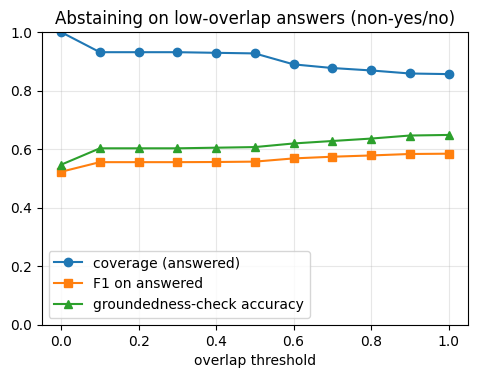

In [33]:
rows = []
for t in np.round(np.arange(0.0, 1.01, 0.1), 1):
    kept = checked[checked['overlap'] >= t]
    abstain_preds = ['' if (not ground.yes_no[i]) and ground.overlap[i] < t else ground.pred[i]
                     for i in range(len(ground))]
    rows.append({'threshold': t,
                 'coverage': len(kept) / len(checked),                 # fraction still answered
                 'F1 on answered': kept['F1'].mean() if len(kept) else np.nan,
                 'check accuracy': ((checked['overlap'] >= t) == checked['correct']).mean(),
                 'EM all questions': np.mean([exact_match(p, a) for p, a in zip(abstain_preds, answers)]),
                 'F1 all questions': np.mean([f1_score(p, a) for p, a in zip(abstain_preds, answers)])})
sweep = pd.DataFrame(rows).round(4)
display(sweep)

plt.figure(figsize=(5.5, 3.8))
plt.plot(sweep['threshold'], sweep['coverage'], marker='o', label='coverage (answered)')
plt.plot(sweep['threshold'], sweep['F1 on answered'], marker='s', label='F1 on answered')
plt.plot(sweep['threshold'], sweep['check accuracy'], marker='^', label='groundedness-check accuracy')
plt.xlabel('overlap threshold'); plt.ylim(0, 1); plt.grid(alpha=.3); plt.legend()
plt.title('Abstaining on low-overlap answers (non-yes/no)')
plt.savefig(f'{OUT}/task3_threshold_sweep.png', dpi=150, bbox_inches='tight'); plt.show()

## 3.5 The check on the hybrid answers, and examples
We apply the same check to the hybrid answers (`checked_h`), and list Task 2 examples from three cells of the 2×2 table:
- wrong answers that pass the check;
- correct answers that are flagged;
- wrong answers that are caught.

In [34]:
checked_h = groundedness_frame(hybrid_preds, hybrid_ranked)
checked_h = checked_h[~checked_h['yes_no']].copy()
hybrid_ground_table = pd.DataFrame([check_report(checked, 'Task 2 answers (dense top-5)'),
                                    check_report(checked_h, 'Task 3 answers (hybrid top-5)')]).round(4)
display(hybrid_ground_table)

pd.set_option('display.max_colwidth', 70)
cols = ['question', 'gold', 'pred', 'overlap']
print('Incorrect but HIGH overlap (copied words from the wrong place):')
display(checked[(~checked.correct) & (checked.grounded)].head(5)[cols])
print('Correct but LOW overlap (flagged although right):')
display(checked[(checked.correct) & (~checked.grounded)].head(5)[cols])
print('Incorrect and LOW overlap (caught by the check):')
display(checked[(~checked.correct) & (~checked.grounded)].head(5)[cols])

,Answers,N,correct,flagged,correct w/ high overlap,incorrect w/ low overlap,check accuracy,balanced accuracy,majority baseline
0,Task 2 answers (dense top-5),481,263,35,0.9886,0.1468,0.6071,0.5677,0.5468
1,Task 3 answers (hybrid top-5),489,285,40,0.9719,0.1569,0.6319,0.5644,0.5828


Incorrect but HIGH overlap (copied words from the wrong place):


,question,gold,pred,overlap
5,What did The Legal Tender Act of 1862 establish?,"the United States Note, the first paper currency in United States ...",United States Note,1.0
12,Which county was Lincoln born in?,Hardin County,Kentucky,1.0
16,Who was the general in charge at the Battle of Antietam?,General McClellan,Lincoln,1.0
17,Why did Lincoln issue the Emancipation Proclamation?,To free slaves,To weaken the rebellion,1.0
28,Who graduated in ecclesiastical law at the early age of 20 and beg...,Amedeo Avogadro,He,1.0


Correct but LOW overlap (flagged although right):


,question,gold,pred,overlap
428,When did John Adams serve as Vice President?,1789-1797,1789-1797,0.0
554,Did Fillmore form a law partnership before or after he founded the...,Before.,before,0.0
893,When was Woodrow Wilson born?,"December 28, 1856",1856,0.0


Incorrect and LOW overlap (caught by the check):


,question,gold,pred,overlap
21,How old was Lincoln in 1816?,seven,7,0.0
54,What happened from 1730 to 1744?,He was professor of astronomy at Uppsala University,Not specified,0.0
55,What happened in 1745?,The scale was reversed,No information provided.,0.0
64,What are the similarities between beetles and grasshoppers?,mouthparts,None,0.0
138,What arrived in Britain?,The first Canadian Army units in WW II,Immigrants,0.0


## 3.6 Significance tests and further analysis
The differences between the systems are small, so we test them with exact paired McNemar tests on the same questions. We also look more closely at what the groundedness check misses and what it catches.

In [35]:
def mcnemar(a, b):
    # exact paired test: how often b is right where a is wrong, and the reverse
    up = sum(x == 0 and y == 1 for x, y in zip(a, b)); down = sum(x == 1 and y == 0 for x, y in zip(a, b))
    n, k = up + down, min(up, down)
    p = min(1.0, 2 * sum(math.comb(n, j) for j in range(k + 1)) / 2 ** n) if n else 1.0
    return up, down, p

# 1) Retrieval: paired comparison on factual questions
for k in [1, 5, 10]:
    hit = lambda R, i: float(first_hit_rank(R[i][:k], answers[i]) <= k)
    hb, hd, hh = ([hit(R, i) for i in keep] for R in (bm25_ranked, dense_ranked, hybrid_ranked))
    (u1, d1, p1), (u2, d2, p2) = mcnemar(hb, hh), mcnemar(hd, hh)
    print(f'1) R@{k:<2} hybrid vs BM25: +{u1}/-{d1} (p={p1:.3f}) | hybrid vs dense: +{u2}/-{d2} (p={p2:.3f})')
same_top = sum(h[0] in (b[0], d[0]) for h, b, d in zip(hybrid_ranked, bm25_ranked, dense_ranked))
print(f'   fused #1 passage is the BM25 #1 or the dense #1 for {same_top}/{len(questions)} questions')

# 2) Answers: paired comparison of EM, Task 2 vs hybrid
up, down, p = mcnemar([exact_match(task2_preds[i], answers[i]) for i in range(len(questions))],
                      [exact_match(hybrid_preds[i], answers[i]) for i in range(len(questions))])
print(f'2) EM hybrid vs Task 2: fixed {up}, broken {down} (p={p:.3f}); '
      f'answers changed: {sum(a != b for a, b in zip(task2_preds, hybrid_preds))}/{len(questions)}')

# 3) Groundedness: shape of the overlap scores and what the check misses / catches
ov = checked['overlap']
print(f'3) overlap = 1.0: {(ov == 1).sum()}, = 0.0: {(ov == 0).sum()}, in between: {((ov > 0) & (ov < 1)).sum()} (of {len(checked)})')
missed = checked[(~checked.correct) & (checked.grounded)]
print(f'   incorrect but high overlap: {len(missed)}; partly right (0 < F1 < 0.5): {((missed.F1 > 0) & (missed.F1 < 0.5)).sum()}, '
      f'F1 = 0: {(missed.F1 == 0).sum()}')
flagged = checked[~checked.grounded]
refusal = flagged['pred'].str.contains(r'not (?:specified|provided|mentioned)|no information|^none\.?$', case=False)
numeric = flagged['pred'].str.fullmatch(r'[\d/.,\- ]+')
print(f'   flagged: {len(flagged)} -> model non-answers ("Not specified", "None", ...): {refusal.sum()}, '
      f'bare numbers: {numeric.sum()}, correct but flagged: {flagged.correct.sum()} {list(flagged[flagged.correct].pred)}')

1) R@1  hybrid vs BM25: +31/-34 (p=0.804) | hybrid vs dense: +63/-21 (p=0.000)
1) R@5  hybrid vs BM25: +20/-15 (p=0.500) | hybrid vs dense: +34/-16 (p=0.015)
1) R@10 hybrid vs BM25: +16/-5 (p=0.027) | hybrid vs dense: +30/-13 (p=0.014)
   fused #1 passage is the BM25 #1 or the dense #1 for 792/918 questions
2) EM hybrid vs Task 2: fixed 38, broken 31 (p=0.470); answers changed: 288/918
3) overlap = 1.0: 412, = 0.0: 33, in between: 36 (of 481)
   incorrect but high overlap: 186; partly right (0 < F1 < 0.5): 71, F1 = 0: 115
   flagged: 35 -> model non-answers ("Not specified", "None", ...): 8, bare numbers: 9, correct but flagged: 3 ['1789-1797', 'before', '1856']


## 3.7 Saving the results
`task3_results.json` contains:
- the fused rankings and the hybrid answers;
- all comparison and groundedness tables, the overlap scores and the threshold sweep;
- the dataset ids of the ranked passages and the configuration;
- SHA-256 hashes of `task1_results.json` and `task2_results.json` written earlier in this run, which records exactly which Task 1 and Task 2 results were combined.

In [36]:
if QUICK_TEST:
    print('QUICK_TEST is on - results NOT saved. Set QUICK_TEST = False and run all.')
else:
    task1_file, task2_file = f'{OUT}/task1_results.json', f'{OUT}/task2_results.json'
    with open(f'{OUT}/task3_results.json', 'w') as f:
        json.dump({'hybrid_ranked': hybrid_ranked,
                   'preds': hybrid_preds,
                   'comparison_all': compare_all.to_dict(orient='records'),
                   'comparison_no_yes_no': compare_fact.to_dict(orient='records'),
                   'groundedness': ground_table.to_dict(orient='records'),
                   'overlap_task2': ground['overlap'].tolist(),
                   'sweep': sweep.to_dict(orient='records'),
                   'passage_ids': passage_ids,           # dataset ids of the ranked positions
                   'config': {'rrf_c': RRF_C, 'top_k': TOP_K, 'threshold': THRESH,
                              'correct_f1': CORRECT_F1, 'llm': LLM_NAME, 'batch_size': BATCH_SIZE,
                              'dataset_revision': DATASET_REVISION,
                              'inputs': {os.path.basename(p): hashlib.sha256(open(p, 'rb').read()).hexdigest()
                                         for p in (task1_file, task2_file)}}}, f)
    print('saved', f'{OUT}/task3_results.json')

saved Output_Final/task3_results.json


## 3.8 Discussion (Task 3)
*The numbers below are from the full run (`QUICK_TEST = False`) stored in `Output_Final/`.*

**Hybrid retrieval.** Fusing the BM25 and dense rankings with RRF (c = 60) gives the best Recall@k at k = 3, 5 and 10, both on all questions (R@10 0.404 vs 0.395 for BM25 and 0.380 for dense) and on the 498 factual questions:

| Factual questions | R@1 | R@3 | R@5 | R@10 |
|---|---|---|---|---|
| BM25 (Task 1) | 0.490 | 0.586 | 0.627 | 0.657 |
| Dense (Task 2) | 0.400 | 0.538 | 0.600 | 0.645 |
| Hybrid RRF (Task 3) | 0.484 | 0.600 | 0.637 | 0.679 |

At k = 1 fusion does not help (0.484 vs 0.490 for BM25; +31/−34 questions). The fused first passage is almost always one of the two retrievers' first passages (792 of 918 questions), so RRF mostly re-orders ranks 2–10.

In paired McNemar tests on the factual questions:
- **vs dense retrieval:** the gain is significant at every k (e.g. R@1 +63/−21, p < 0.001);
- **vs BM25:** the gain is significant only at k = 10 (+16/−5, p = 0.027), not at k = 5 (+20/−15, p = 0.50).

BM25 is already a strong retriever on this entity-heavy dataset. The hybrid's extra value lies in recovering answers that only the dense retriever finds.

**Effect on the answers.** With the same LLM, prompt, truncation, decoding and batch size as Task 2, only the retriever changes. EM rises from 0.564 to **0.572** and F1 from 0.671 to **0.684**; on the factual questions EM goes from 0.313 to 0.341 and F1 from 0.505 to 0.541. The gain is small and **not statistically significant**: 38 questions are fixed and 31 broken (p = 0.47), although 288 answers changed. Yes/no accuracy is slightly lower (0.864 vs 0.879). Better recall only partly reaches the answers, because many of the remaining errors come from the generator rather than from retrieval.

**Groundedness check.** On the 481 non-yes/no Task 2 answers, **98.9% of the correct answers have high overlap** (260 of 263), but only **14.7% of the incorrect answers have low overlap** (32 of 218). The check's accuracy is **0.607**, only a little above the 0.547 of never flagging anything (balanced accuracy 0.568). With exact match as the definition of correct, it is even worse than never flagging (0.389 vs 0.676).

The overlap score is almost binary: 412 of the 481 answers score exactly 1.0 and 33 score 0.0. The LLM nearly always copies words from the passages, so most errors are *grounded but wrong*:
- a span from the wrong place, such as *"Kentucky"* instead of *"Hardin County"*;
- or an answer that is only partly right (71 of the 186 incorrect, high-overlap answers have 0 < F1 < 0.5).

What the check does catch is real:
- 8 non-answers such as *"Not specified"* and *"No information provided."*;
- numbers the model computed or wrote as digits (*"7"* vs *"seven"*);
- a few invented answers (*"Immigrants"*).

Only 3 correct answers are flagged:
- *"1789-1797"*, because normalisation merges the two years into one token;
- *"before"*, because it is a stop-word;
- *"1856"* (Woodrow Wilson's birth year), which appears in none of the retrieved passages. This is a correct answer the model knew from memory, exactly the kind of ungrounded answer the check is meant to expose.

The hybrid answers show the same picture (accuracy 0.632 vs 0.583 for never flagging).

**Abstaining.** At threshold 0.5 the system still answers 92.7% of the checked questions, and F1 on those rises from 0.523 to 0.557. Overall EM, however, drops slightly (0.564 → 0.562), because the flagged answers were mostly wrong already and abstaining also removes a few correct ones. The threshold sweep peaks at 1.0 (check accuracy 0.649), but we chose that threshold on the test questions themselves, so it is an analysis rather than a tuned result.

**Limitations.** Recall@k is measured by answer-string matching, and "correct" is defined by an F1 threshold, so both depend on how the gold answers are phrased. The overlap check works on surface words only: it cannot recognise paraphrases, and it cannot tell whether a copied span actually answers the question.

**Conclusion.** Hybrid retrieval is a cheap and reliable improvement in recall, especially over dense retrieval and at larger k, but on this dataset it barely moves EM and F1. Lexical overlap is a useful warning sign for answers that do not come from the evidence (non-answers, invented, computed or remembered answers), which matches the hallucination motivation of the project. It cannot detect the most common failure, however: a fluent answer copied from the wrong place in the retrieved passages. Catching that would need a semantic check, for example entailment between passage, question and answer, rather than word overlap.

---
# Part 4 – Final summary

## 4.1 Results across the three tasks
All required metrics in one place, computed in this run: EM, F1 and Recall@k for the three systems (all questions and factual questions), yes/no accuracy, and the groundedness-check results for the Task 2 and Task 3 answers.

In [37]:
print('EM / F1 / Recall@k - all questions and factual (non-yes/no) questions')
display(pd.concat([compare_all, compare_fact], ignore_index=True))

print('Yes/no accuracy (420 yes/no questions)')
display(yesno_acc)

print(f'Groundedness check (overlap threshold {THRESH}, correct = F1 >= {CORRECT_F1})')
display(hybrid_ground_table)

EM / F1 / Recall@k - all questions and factual (non-yes/no) questions


,System,N,EM,F1,R@1,R@3,R@5,R@10
0,Task 1: BM25 + extractive,918,0.0185,0.0553,0.2734,0.3333,0.3627,0.3954
1,Task 2: Dense + LLM,918,0.5643,0.6710,0.2266,0.3061,0.3442,0.3802
2,Task 3: Hybrid (RRF) + LLM,918,0.5719,0.6836,0.2723,0.3420,0.3682,0.4041
3,Task 1: BM25 + extractive (no yes/no),498,0.0341,0.0991,0.4900,0.5863,0.6265,0.6566
4,Task 2: Dense + LLM (no yes/no),498,0.3133,0.5049,0.3996,0.5382,0.6004,0.6446
5,Task 3: Hybrid (RRF) + LLM (no yes/no),498,0.3414,0.5411,0.4839,0.6004,0.6365,0.6787


Yes/no accuracy (420 yes/no questions)


,System,yes/no accuracy
0,Task 1: BM25 + extractive,0.0024
1,Task 2: Dense + LLM,0.8786
2,Task 3: Hybrid (RRF) + LLM,0.8643


Groundedness check (overlap threshold 0.5, correct = F1 >= 0.5)


,Answers,N,correct,flagged,correct w/ high overlap,incorrect w/ low overlap,check accuracy,balanced accuracy,majority baseline
0,Task 2 answers (dense top-5),481,263,35,0.9886,0.1468,0.6071,0.5677,0.5468
1,Task 3 answers (hybrid top-5),489,285,40,0.9719,0.1569,0.6319,0.5644,0.5828


## 4.2 Output files
The cell lists every file written to the output folder. In Colab without Google Drive the runtime's disk is temporary, so the folder is also downloaded as `Output_Final.zip`.

In [38]:
print('Files in', os.path.abspath(OUT))
for name in sorted(os.listdir(OUT)):
    print(f'  {name:<42} {os.path.getsize(os.path.join(OUT, name)) / 1024:8.1f} KB')

if IN_COLAB and not USE_DRIVE and not QUICK_TEST:
    import shutil
    files.download(shutil.make_archive('Output_Final', 'zip', OUT))   # Colab disk is temporary

Files in /content/Output_Final
  task1_recall.png                               32.2 KB
  task1_results.json                            571.3 KB
  task2_generation_cache.json                    15.2 KB
  task2_recall.png                               47.9 KB
  task2_results.json                            542.9 KB
  task3_hybrid_generation_cache.json             16.6 KB
  task3_overlap_hist.png                         38.0 KB
  task3_recall_compare.png                       50.0 KB
  task3_results.json                            549.9 KB
  task3_threshold_sweep.png                      47.4 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 4.3 Overall conclusions
*Numbers from the full run stored in `Output_Final/` (918 questions, 3,200 passages).*

| System | EM | F1 | R@1 | R@3 | R@5 | R@10 | R@5 (factual) | R@10 (factual) |
|---|---|---|---|---|---|---|---|---|
| Task 1: BM25 + extractive | 0.019 | 0.055 | 0.273 | 0.333 | 0.363 | 0.395 | 0.627 | 0.657 |
| Task 2: Dense + LLM (RAG) | 0.564 | 0.671 | 0.227 | 0.306 | 0.344 | 0.380 | 0.600 | 0.645 |
| Task 3: Hybrid (RRF) + LLM | **0.572** | **0.684** | 0.272 | **0.342** | **0.368** | **0.404** | **0.637** | **0.679** |

We checked the 481 Task 2 answers that are not just "yes" or "no". Almost all correct answers (98.9%) use words that appear in the retrieved passages. But the check catches only 14.7% of the wrong answers. Overall it is right 60.7% of the time, only a little better than never flagging anything (54.7%).

1. **The LLM made the biggest difference.** EM jumped from 0.019 in Task 1 to 0.564 in Task 2. This came from replacing the simple "pick the longest phrase" rule with an LLM that writes the answer. Retrieval did not help: dense retrieval (MiniLM) finds the answer passage slightly less often than BM25 at every k. Many questions ask about specific names, places and dates, and exact word matching handles these well.
2. **BM25 and dense retrieval find different passages, so combining them helps.** Their top-5 lists share only about one third of their passages. Merging the two rankings with Reciprocal Rank Fusion gives the best recall at k = 3, 5 and 10. It is clearly better than dense retrieval at every k, but better than BM25 by a significant margin only at k = 10.
3. **Better retrieval improved the answers only a little.** We kept the same LLM and changed only the retriever. EM went from 0.564 to 0.572 and F1 from 0.671 to 0.684. This difference is too small to count: 38 answers became correct but 31 became wrong (p = 0.47). Most remaining mistakes happen because the LLM picks the wrong part of the passages it was given, not because the right passage is missing.
4. **Word overlap catches only some bad answers.** It works well for answers that do not come from the passages: non-answers such as "Not specified", numbers the model worked out or wrote differently, and answers from the model's own memory. But the most common mistake is an answer copied from the wrong part of a passage. Such an answer still shares words with the passage, so the check cannot catch it. A check that understands meaning, for example testing whether the passage really supports the answer, would be the next step.

---
## References
- P. Lewis, E. Perez, A. Piktus et al. (2020). *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks.* NeurIPS. arXiv:2005.11401
- D. Chen, A. Fisch, J. Weston and A. Bordes (2017). *Reading Wikipedia to Answer Open-Domain Questions* (DrQA). ACL.
- V. Karpukhin, B. Oğuz, S. Min et al. (2020). *Dense Passage Retrieval for Open-Domain Question Answering.* EMNLP. (answer-string Recall@k; reference retriever: https://github.com/facebookresearch/DPR)
- S. Robertson and H. Zaragoza (2009). *The Probabilistic Relevance Framework: BM25 and Beyond.* Foundations and Trends in Information Retrieval.
- G. V. Cormack, C. L. A. Clarke and S. Büttcher (2009). *Reciprocal Rank Fusion Outperforms Condorcet and Individual Rank Learning Methods.* SIGIR.
- P. Rajpurkar, J. Zhang, K. Lopyrev and P. Liang (2016). *SQuAD: 100,000+ Questions for Machine Comprehension of Text.* EMNLP. (EM/F1 and answer normalisation)
- N. Reimers and I. Gurevych (2019). *Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks.* EMNLP-IJCNLP.
- W. Wang, F. Wei, L. Dong et al. (2020). *MiniLM: Deep Self-Attention Distillation for Task-Agnostic Compression of Pre-Trained Transformers.* NeurIPS.
- J. Johnson, M. Douze and H. Jégou (2019). *Billion-scale Similarity Search with GPUs.* IEEE Transactions on Big Data. (FAISS)
- Qwen Team (2024). *Qwen2.5 Technical Report.* arXiv:2412.15115
- Z. Ji, N. Lee, R. Frieske et al. (2023). *Survey of Hallucination in Natural Language Generation.* ACM Computing Surveys.
- Q. McNemar (1947). *Note on the Sampling Error of the Difference between Correlated Proportions or Percentages.* Psychometrika.
- Tools: [`rank_bm25`](https://github.com/dorianbrown/rank_bm25), [spaCy](https://spacy.io), [Hugging Face Datasets](https://huggingface.co/docs/datasets), [sentence-transformers](https://www.sbert.net), [FAISS](https://github.com/facebookresearch/faiss), [Transformers](https://huggingface.co/docs/transformers).